In [1]:
# step1_prepare_index_images_kaggle.py
# ---------------------------------------------
# Purpose:
#   - Scan your 3 modality folders (all images)
#   - Build label map (person -> class id)
#   - Create subject-wise train/val/test splits
#   - Save: /kaggle/working/metadata/{label_map.json, splits.json, index.csv}
#
# Run: just execute this cell in Kaggle.

import json
import random
from pathlib import Path
import pandas as pd
import sys

# ---------- CONFIG ----------
# Change ROOT_DIR if your dataset path is different.
ROOT_DIR = Path("/kaggle/input/datasets/mdabujohab/casia-final124/CASIA_B124")

# Prefer canonical names; fallbacks handled below.
SKELETON_DIRNAME   = "Skeleton"
SILHOUETTE_NAMES   = "Silhouette"  # handle both
HEATMAP_DIRNAME    = "Heatmap"

IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

# ---------- HELPERS ----------
def list_images(p: Path):
    return sorted([f for f in p.glob("*") if f.is_file() and f.suffix.lower() in IMG_EXTS])

def get_person_dirs(modality_root: Path):
    if not modality_root.exists():
        raise FileNotFoundError(f"Missing modality folder: {modality_root}")
    return {d.name: d for d in sorted(modality_root.iterdir()) if d.is_dir()}

def make_label_map(person_ids):
    return {pid: i for i, pid in enumerate(sorted(person_ids))}

def subject_splits(person_ids, train=0.7, val=0.15, test=0.15, seed=1337):
    assert abs((train + val + test) - 1.0) < 1e-6, "train/val/test must sum to 1"
    rng = random.Random(seed)
    pids = sorted(person_ids)
    rng.shuffle(pids)
    n = len(pids)
    n_train = int(round(n * train))
    n_val   = int(round(n * val))
    n_test  = n - n_train - n_val
    return {"train": pids[:n_train],
            "val":   pids[n_train:n_train+n_val],
            "test":  pids[n_train+n_val:]}

def pick_existing(root: Path, names):
    """Return the first existing subfolder from a list of candidate names."""
    if isinstance(names, str):
        p = root / names
        if p.exists():
            return p
        raise FileNotFoundError(f"Folder not found: {p}")
    for name in names:
        p = root / name
        if p.exists():
            return p
    raise FileNotFoundError(f"None of these folders exist under {root}: {names}")

# ---------- MAIN ----------
def main():
    root = ROOT_DIR

    skel_root = pick_existing(root, SKELETON_DIRNAME)
    sil_root  = pick_existing(root, SILHOUETTE_NAMES)  # handles both spellings
    heat_root = pick_existing(root, HEATMAP_DIRNAME)

    # 1) Collect person directories
    skel_dirs = get_person_dirs(skel_root)
    sil_dirs  = get_person_dirs(sil_root)
    heat_dirs = get_person_dirs(heat_root)

    skel_ids = set(skel_dirs.keys())
    sil_ids  = set(sil_dirs.keys())
    heat_ids = set(heat_dirs.keys())

    # Persons present in ALL three modalities
    common_ids = sorted(list(skel_ids & sil_ids & heat_ids))
    missing_any = sorted(list((skel_ids | sil_ids | heat_ids) - set(common_ids)))

    if not common_ids:
        raise RuntimeError(
            "No common person IDs across all modalities. "
            f"Counts — skeleton:{len(skel_ids)}, silhouette:{len(sil_ids)}, heatmap:{len(heat_ids)}. "
            "Check folder names and contents."
        )

    # 2) Build label map
    label_map = make_label_map(common_ids)

    # 3) Summarize per person
    rows = []
    for pid in common_ids:
        n_skel = len(list_images(skel_dirs[pid]))
        n_sil  = len(list_images(sil_dirs[pid]))
        n_heat = len(list_images(heat_dirs[pid]))

        rows.append({
            "person_id": pid,
            "label": label_map[pid],
            "skeleton_dir": str(skel_dirs[pid]),
            "n_skeleton": n_skel,
            "silhouette_dir": str(sil_dirs[pid]),
            "n_silhouette": n_sil,
            "heatmap_dir": str(heat_dirs[pid]),
            "n_heatmap": n_heat,
        })

    df = pd.DataFrame(rows).sort_values("label").reset_index(drop=True)

    # 4) Subject-exclusive splits (identity-safe)
    splits = subject_splits(common_ids, train=0.70, val=0.15, test=0.15, seed=1337)
    pid2split = {pid: split for split, lst in splits.items() for pid in lst}
    df["split"] = df["person_id"].map(pid2split)

    # 5) Save under /kaggle/working (writable)
    meta_dir = Path("/kaggle/working/metadata")
    meta_dir.mkdir(parents=True, exist_ok=True)

    (meta_dir / "label_map.json").write_text(json.dumps(label_map, indent=2))
    (meta_dir / "splits.json").write_text(json.dumps(splits, indent=2))
    df.to_csv(meta_dir / "index.csv", index=False)

    # 6) Summary
    print("=== Dataset Summary ===")
    print(f"Root: {root}")
    print(f"Persons with all 3 modalities: {len(common_ids)}")
    if missing_any:
        print(f"Persons missing at least one modality: {len(missing_any)} (e.g., {missing_any[:8]})")
    print("\nCounts by split:")
    print(df["split"].value_counts())
    print("\nFirst rows:")
    print(df.head())
    print(f"\nSaved to: {meta_dir}")

# Kaggle/Colab fix: ignore injected -f arguments
if __name__ == "__main__":
    sys.argv = sys.argv[:1]
    main()


=== Dataset Summary ===
Root: /kaggle/input/datasets/mdabujohab/casia-final124/CASIA_B124
Persons with all 3 modalities: 124

Counts by split:
split
train    87
val      19
test     18
Name: count, dtype: int64

First rows:
  person_id  label                                       skeleton_dir  \
0  person00      0  /kaggle/input/datasets/mdabujohab/casia-final1...   
1  person01      1  /kaggle/input/datasets/mdabujohab/casia-final1...   
2  person02      2  /kaggle/input/datasets/mdabujohab/casia-final1...   
3  person03      3  /kaggle/input/datasets/mdabujohab/casia-final1...   
4  person04      4  /kaggle/input/datasets/mdabujohab/casia-final1...   

   n_skeleton                                     silhouette_dir  \
0         175  /kaggle/input/datasets/mdabujohab/casia-final1...   
1         185  /kaggle/input/datasets/mdabujohab/casia-final1...   
2         191  /kaggle/input/datasets/mdabujohab/casia-final1...   
3         198  /kaggle/input/datasets/mdabujohab/casia-final1... 

In [2]:
# step2_dataloaders.py
# ----------------------------------------------------------
# Multi-modal Dataset (images-only):
#   - Skeleton: single image -> 2D CNN input (C,H,W)
#   - Silhouette: clip of T images -> 3D CNN input (C,T,H,W)
#   - Heatmap:   clip of T images -> 3D CNN input (C,T,H,W)
#
# Reads metadata from /kaggle/working/metadata/{index.csv,label_map.json}
# which you created in Step 1.

import json, math, random
from pathlib import Path
from typing import List, Dict, Tuple

import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as T

# ---------------- Config ----------------
META_DIR = Path("/kaggle/working/metadata")   # Step-1 outputs live here
INDEX_CSV = META_DIR / "index.csv"
LABEL_MAP_JSON = META_DIR / "label_map.json"

SEED = 1337
random.seed(SEED)

# Image/clip settings
IMG_SIZE = 224       # resize shorter side then center/resize crop to square
T_CLIP   = 16        # number of frames per clip for 3D CNN
STRIDE   = 4         # step between consecutive clip starts when enumerating
USE_RANDOM_CLIP_TRAIN = True  # random starting offset during training

# ---------------- Helpers ----------------
IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

def list_images_sorted(folder: Path) -> List[Path]:
    imgs = [p for p in folder.glob("*") if p.is_file() and p.suffix.lower() in IMG_EXTS]
    return sorted(imgs)

def loop_take(seq: List[Path], n: int, start: int = 0) -> List[Path]:
    """Take n items from seq with wrap-around, starting at index 'start'."""
    if len(seq) == 0:
        return []
    return [seq[(start + i) % len(seq)] for i in range(n)]

# ---------------- Transforms ----------------
# 2D (skeleton)
train_tf_2d = T.Compose([
    T.Resize(IMG_SIZE),
    T.CenterCrop(IMG_SIZE),
    T.ToTensor(),
    T.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])
val_tf_2d = train_tf_2d  # keep same unless you want weaker val/test augs

# Per-frame transform used for 3D stacks
train_tf_frame = T.Compose([
    T.Resize(IMG_SIZE),
    T.CenterCrop(IMG_SIZE),
    T.ToTensor(),
    T.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])
val_tf_frame = train_tf_frame

# ---------------- Dataset ----------------
class MultiModalGaitDataset(Dataset):
    """
    One sample = {
        'skel':  torch.FloatTensor (C,H,W),
        'sil':   torch.FloatTensor (C,T,H,W),
        'heat':  torch.FloatTensor (C,T,H,W),
        'label': int,
        'person_id': str
    }
    """
    def __init__(self, index_csv: Path, split: str, t_clip: int = 16, stride: int = 4,
                 train_mode: bool = True):
        assert split in {"train", "val", "test"}
        self.df = pd.read_csv(index_csv)
        self.df = self.df[self.df["split"] == split].reset_index(drop=True)
        self.t_clip = t_clip
        self.stride = max(1, stride)
        self.train_mode = train_mode

        # Choose transforms
        self.tf2d = train_tf_2d if train_mode else val_tf_2d
        self.tfframe = train_tf_frame if train_mode else val_tf_frame

        # Build an expanded index of (person_id, clip_start) for 3D modalities
        self.samples = []  # each item: dict with person, label, starts
        for _, row in self.df.iterrows():
            pid = row["person_id"]
            label = int(row["label"])
            skel_dir = Path(row["skeleton_dir"])
            sil_dir  = Path(row["silhouette_dir"])
            heat_dir = Path(row["heatmap_dir"])

            skel_imgs = list_images_sorted(skel_dir)
            sil_imgs  = list_images_sorted(sil_dir)
            heat_imgs = list_images_sorted(heat_dir)

            # enumerate possible clip starts using sil_imgs as reference
            # (could also use min count of both)
            n_ref = max(len(sil_imgs), len(heat_imgs))
            if n_ref == 0 and len(skel_imgs) == 0:
                continue

            if n_ref >= self.t_clip:
                starts = list(range(0, n_ref - self.t_clip + 1, self.stride))
                if len(starts) == 0:
                    starts = [0]
            else:
                # not enough frames => still create at least one clip with looping
                starts = [0]

            for st in starts:
                self.samples.append({
                    "person_id": pid,
                    "label": label,
                    "skel_dir": skel_dir,
                    "sil_dir": sil_dir,
                    "heat_dir": heat_dir,
                    "skel_imgs": skel_imgs,
                    "sil_imgs": sil_imgs,
                    "heat_imgs": heat_imgs,
                    "start": st,
                    "n_ref": n_ref
                })

        # Fallback: if no 3D frames exist but skeleton exists, still create samples
        if len(self.samples) == 0:
            for _, row in self.df.iterrows():
                pid = row["person_id"]
                label = int(row["label"])
                self.samples.append({
                    "person_id": pid,
                    "label": label,
                    "skel_dir": Path(row["skeleton_dir"]),
                    "sil_dir":  Path(row["silhouette_dir"]),
                    "heat_dir": Path(row["heatmap_dir"]),
                    "skel_imgs": list_images_sorted(Path(row["skeleton_dir"])),
                    "sil_imgs":  list_images_sorted(Path(row["silhouette_dir"])),
                    "heat_imgs": list_images_sorted(Path(row["heatmap_dir"])),
                    "start": 0,
                    "n_ref": 0
                })

        # Small shuffle for train
        if self.train_mode:
            random.shuffle(self.samples)

    def __len__(self):
        return len(self.samples)

    def _load_image(self, p: Path, tf: T.Compose):
        img = Image.open(p).convert("RGB")
        return tf(img)

    def _make_clip(self, frames: List[Path], start: int, t: int, randomize: bool):
        # Pick frames for a clip; if not enough, loop
        if len(frames) == 0:
            return None
        if len(frames) >= t:
            if randomize and USE_RANDOM_CLIP_TRAIN:
                # random start bounded by valid region
                max_start = max(0, len(frames) - t)
                start = random.randint(0, max_start)
            idxs = list(range(start, start + t))
            seq = [frames[i] for i in idxs]
        else:
            seq = loop_take(frames, t, start=0)
        # Load and stack to (T, C, H, W)
        tensors = [self._load_image(p, self.tfframe) for p in seq]
        clip = torch.stack(tensors, dim=0)           # (T,C,H,W)
        clip = clip.permute(1, 0, 2, 3).contiguous() # (C,T,H,W) for 3D CNN
        return clip

    def __getitem__(self, idx):
        s = self.samples[idx]

        # Skeleton: choose one image (random for train, else first)
        if len(s["skel_imgs"]) > 0:
            if self.train_mode:
                skel_path = random.choice(s["skel_imgs"])
            else:
                skel_path = s["skel_imgs"][0]
            skel = self._load_image(skel_path, self.tf2d)  # (C,H,W)
        else:
            # if missing, create a dummy zero image
            skel = torch.zeros(3, IMG_SIZE, IMG_SIZE, dtype=torch.float32)

        # Silhouette clip
        sil = self._make_clip(s["sil_imgs"], s["start"], self.t_clip, randomize=self.train_mode)
        if sil is None:
            sil = torch.zeros(3, self.t_clip, IMG_SIZE, IMG_SIZE, dtype=torch.float32)

        # Heatmap clip
        heat = self._make_clip(s["heat_imgs"], s["start"], self.t_clip, randomize=self.train_mode)
        if heat is None:
            heat = torch.zeros(3, self.t_clip, IMG_SIZE, IMG_SIZE, dtype=torch.float32)

        label = int(s["label"])
        return {
            "skel": skel,          # (C,H,W)
            "sil": sil,            # (C,T,H,W)
            "heat": heat,          # (C,T,H,W)
            "label": label,
            "person_id": s["person_id"],
        }

# ---------------- Loader factory ----------------
def make_loaders(index_csv: Path = INDEX_CSV,
                 t_clip: int = T_CLIP, stride: int = STRIDE,
                 batch2d: int = 32, batch3d: int = 8,
                 num_workers: int = 2):

    # Same dataset class for all splits; batch size driven by the heaviest (3D) tensors
    ds_tr = MultiModalGaitDataset(index_csv, split="train", t_clip=t_clip, stride=stride, train_mode=True)
    ds_va = MultiModalGaitDataset(index_csv, split="val",   t_clip=t_clip, stride=stride, train_mode=False)
    ds_te = MultiModalGaitDataset(index_csv, split="test",  t_clip=t_clip, stride=stride, train_mode=False)

    # Use a single batch size tuned for 3D tensors; skeleton is lighter and will fit
    # If GPU memory is tight, reduce batch_size.
    loader_tr = DataLoader(ds_tr, batch_size=batch3d, shuffle=True,  num_workers=num_workers,
                           pin_memory=True, drop_last=False)
    loader_va = DataLoader(ds_va, batch_size=batch3d, shuffle=False, num_workers=num_workers,
                           pin_memory=True, drop_last=False)
    loader_te = DataLoader(ds_te, batch_size=batch3d, shuffle=False, num_workers=num_workers,
                           pin_memory=True, drop_last=False)

    return loader_tr, loader_va, loader_te

# ---------------- Quick smoke test ----------------
if INDEX_CSV.exists() and LABEL_MAP_JSON.exists():
    print("Building loaders...")
    tr, va, te = make_loaders()
    batch = next(iter(tr))
    print("Batch keys:", list(batch.keys()))
    print("skel:", batch["skel"].shape)   # (B, C, H, W)
    print("sil :", batch["sil"].shape)    # (B, C, T, H, W)
    print("heat:", batch["heat"].shape)   # (B, C, T, H, W)
    print("label:", batch["label"].shape)
else:
    print("Metadata not found. Run Step 1 first to create index.csv and label_map.json.")


Building loaders...
Batch keys: ['skel', 'sil', 'heat', 'label', 'person_id']
skel: torch.Size([8, 3, 224, 224])
sil : torch.Size([8, 3, 16, 224, 224])
heat: torch.Size([8, 3, 16, 224, 224])
label: torch.Size([8])


In [3]:
# === STEP 3: Feature extractors + caching (full code) ===
# Modality encoders:
#   - Skeleton   -> ResNet50 (2D)
#   - Silhouette -> R3D-18 (3D)
#   - Heatmap    -> EfficientNet-B0 (2D frame-wise + temporal average)
#
# Output:
#   - 512-D skeleton feature
#   - 512-D silhouette feature
#   - 512-D heatmap feature
#   - 1536-D fused feature
#
# Saves:
#   /kaggle/working/features/train_features.npz
#   /kaggle/working/features/val_features.npz
#   /kaggle/working/features/test_features.npz
#   and small CSV previews

import os, json, random
from pathlib import Path
from typing import List
import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

# -------------------- Config --------------------
META_DIR = Path("/kaggle/working/metadata")
INDEX_CSV = META_DIR / "index.csv"
LABEL_MAP_JSON = META_DIR / "label_map.json"

assert INDEX_CSV.exists(), "index.csv not found in /kaggle/working/metadata"
assert LABEL_MAP_JSON.exists(), "label_map.json not found in /kaggle/working/metadata"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
FEATURE_DIR = Path("/kaggle/working/features")
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

SEED = 1337
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

IMG_SIZE = 224
T_CLIP = 16
STRIDE = 4
USE_RANDOM_CLIP_TRAIN = True
EMB_DIM = 512

IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

# -------------------- Helpers --------------------
def _list_images_sorted(folder: Path) -> List[Path]:
    return sorted([p for p in folder.glob("*") if p.is_file() and p.suffix.lower() in IMG_EXTS])

def _loop_take(seq: List[Path], n: int, start: int = 0) -> List[Path]:
    if not seq:
        return []
    return [seq[(start + i) % len(seq)] for i in range(n)]

# -------------------- Transforms --------------------
# 2D transforms for skeleton + heatmap frames
train_tf_2d = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

val_tf_2d = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

# 3D transforms for silhouette clip frames
train_tf_3d_frame = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

val_tf_3d_frame = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

# -------------------- Dataset --------------------
class MultiModalGaitDataset(Dataset):
    def __init__(self, index_csv: Path, split: str, t_clip: int = 16, stride: int = 4, train_mode: bool = True):
        assert split in {"train", "val", "test"}
        df = pd.read_csv(index_csv)
        self.df = df[df["split"] == split].reset_index(drop=True)

        self.t_clip = t_clip
        self.stride = max(1, stride)
        self.train_mode = train_mode

        self.tf2d = train_tf_2d if train_mode else val_tf_2d
        self.tf3d = train_tf_3d_frame if train_mode else val_tf_3d_frame

        self.samples = []
        for _, row in self.df.iterrows():
            pid = row["person_id"]
            label = int(row["label"])

            skel_dir = Path(row["skeleton_dir"])
            sil_dir = Path(row["silhouette_dir"])
            heat_dir = Path(row["heatmap_dir"])

            skel_imgs = _list_images_sorted(skel_dir)
            sil_imgs = _list_images_sorted(sil_dir)
            heat_imgs = _list_images_sorted(heat_dir)

            n_ref = max(len(sil_imgs), len(heat_imgs), 1)
            starts = [0] if n_ref < t_clip else list(range(0, n_ref - t_clip + 1, self.stride)) or [0]

            for st in starts:
                self.samples.append({
                    "person_id": pid,
                    "label": label,
                    "skel_imgs": skel_imgs,
                    "sil_imgs": sil_imgs,
                    "heat_imgs": heat_imgs,
                    "start": st
                })

        if self.train_mode:
            random.shuffle(self.samples)

    def __len__(self):
        return len(self.samples)

    def _load_img(self, p: Path, tf):
        img = Image.open(p).convert("RGB")
        return tf(img)

    def _make_clip_3d(self, frames: List[Path], start: int, t: int, randomize: bool):
        # output: (C, T, H, W) for 3D CNN
        if len(frames) == 0:
            return torch.zeros(3, t, IMG_SIZE, IMG_SIZE, dtype=torch.float32)

        if len(frames) >= t:
            if randomize and USE_RANDOM_CLIP_TRAIN:
                start = random.randint(0, max(0, len(frames) - t))
            seq = frames[start:start+t]
        else:
            seq = _loop_take(frames, t, 0)

        tens = [self._load_img(p, self.tf3d) for p in seq]   # list of (C,H,W)
        clip = torch.stack(tens, dim=0).permute(1, 0, 2, 3).contiguous()  # (C,T,H,W)
        return clip

    def _make_clip_2d(self, frames: List[Path], start: int, t: int, randomize: bool):
        # output: (T, C, H, W) for frame-wise 2D model
        if len(frames) == 0:
            return torch.zeros(t, 3, IMG_SIZE, IMG_SIZE, dtype=torch.float32)

        if len(frames) >= t:
            if randomize and USE_RANDOM_CLIP_TRAIN:
                start = random.randint(0, max(0, len(frames) - t))
            seq = frames[start:start+t]
        else:
            seq = _loop_take(frames, t, 0)

        tens = [self._load_img(p, self.tf2d) for p in seq]   # list of (C,H,W)
        clip = torch.stack(tens, dim=0).contiguous()         # (T,C,H,W)
        return clip

    def __getitem__(self, idx):
        s = self.samples[idx]

        # skeleton -> single 2D image
        if len(s["skel_imgs"]) > 0:
            skel_path = random.choice(s["skel_imgs"]) if self.train_mode else s["skel_imgs"][0]
            skel = self._load_img(skel_path, self.tf2d)
        else:
            skel = torch.zeros(3, IMG_SIZE, IMG_SIZE, dtype=torch.float32)

        # silhouette -> 3D clip
        sil = self._make_clip_3d(s["sil_imgs"], s["start"], self.t_clip, self.train_mode)

        # heatmap -> 2D frame sequence
        heat = self._make_clip_2d(s["heat_imgs"], s["start"], self.t_clip, self.train_mode)

        return {
            "skel": skel,                  # (3,H,W)
            "sil": sil,                    # (C,T,H,W)
            "heat": heat,                  # (T,C,H,W)
            "label": int(s["label"]),
            "person_id": s["person_id"]
        }

def make_loaders(batch_size: int = 8, num_workers: int = 2):
    ds_tr = MultiModalGaitDataset(INDEX_CSV, "train", t_clip=T_CLIP, stride=STRIDE, train_mode=True)
    ds_va = MultiModalGaitDataset(INDEX_CSV, "val",   t_clip=T_CLIP, stride=STRIDE, train_mode=False)
    ds_te = MultiModalGaitDataset(INDEX_CSV, "test",  t_clip=T_CLIP, stride=STRIDE, train_mode=False)

    Ltr = DataLoader(ds_tr, batch_size=batch_size, shuffle=True,  num_workers=num_workers, pin_memory=True)
    Lva = DataLoader(ds_va, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)
    Lte = DataLoader(ds_te, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)
    return Ltr, Lva, Lte

# -------------------- Backbones --------------------
class ResNet50Embedder(nn.Module):
    def __init__(self, pretrained: bool = True, out_dim: int = 512):
        super().__init__()
        import torchvision.models as models

        try:
            weights = models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None
            net = models.resnet50(weights=weights)
        except Exception:
            net = models.resnet50(weights=None)

        self.backbone = nn.Sequential(*list(net.children())[:-1])  # -> (B,2048,1,1)
        self.proj = nn.Linear(2048, out_dim)

    def forward(self, x):
        x = self.backbone(x)
        x = torch.flatten(x, 1)   # (B,2048)
        x = self.proj(x)          # (B,512)
        return x

class R3D18Embedder(nn.Module):
    def __init__(self, pretrained: bool = True, out_dim: int = 512):
        super().__init__()
        import torchvision.models.video as vmodels

        try:
            weights = vmodels.R3D_18_Weights.KINETICS400_V1 if pretrained else None
            net = vmodels.r3d_18(weights=weights)
        except Exception:
            net = vmodels.r3d_18(weights=None)

        self.backbone = nn.Sequential(*list(net.children())[:-1])  # -> (B,512,1,1,1)
        self.proj = nn.Linear(512, out_dim)

    def forward(self, x):
        x = self.backbone(x)
        x = torch.flatten(x, 1)   # (B,512)
        x = self.proj(x)          # (B,512)
        return x

class EfficientNetB0Embedder(nn.Module):
    def __init__(self, pretrained: bool = True, out_dim: int = 512):
        super().__init__()
        import torchvision.models as models

        try:
            weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
            net = models.efficientnet_b0(weights=weights)
        except Exception:
            net = models.efficientnet_b0(weights=None)

        self.features = net.features
        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.proj = nn.Linear(1280, out_dim)

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)   # (B,1280)
        x = self.proj(x)          # (B,512)
        return x

def temporal_encode_2d(model: nn.Module, clip: torch.Tensor):
    """
    clip: (B,T,C,H,W)
    returns: (B,512)
    """
    B, T, C, H, W = clip.shape
    x = clip.view(B * T, C, H, W)
    z = model(x)                  # (B*T,512)
    z = z.view(B, T, -1).mean(dim=1)
    return z

# -------------------- Feature extraction --------------------
@torch.no_grad()
def extract_embeddings(model_skel, model_sil, model_heat, loader, desc: str):
    model_skel.eval().to(DEVICE)
    model_sil.eval().to(DEVICE)
    model_heat.eval().to(DEVICE)

    zs, zi, zh, labels, pids = [], [], [], [], []

    for batch in loader:
        skel = batch["skel"].to(DEVICE, non_blocking=True)   # (B,3,H,W)
        sil  = batch["sil"].to(DEVICE, non_blocking=True)    # (B,C,T,H,W)
        heat = batch["heat"].to(DEVICE, non_blocking=True)   # (B,T,C,H,W)

        y = batch["label"].cpu().numpy()
        person = batch["person_id"]

        with torch.cuda.amp.autocast(enabled=(DEVICE.type == "cuda")):
            z_s = model_skel(skel)                 # (B,512)
            z_i = model_sil(sil)                   # (B,512)
            z_h = temporal_encode_2d(model_heat, heat)  # (B,512)

        z_s = F.normalize(z_s, p=2, dim=1).cpu().numpy()
        z_i = F.normalize(z_i, p=2, dim=1).cpu().numpy()
        z_h = F.normalize(z_h, p=2, dim=1).cpu().numpy()

        zs.append(z_s)
        zi.append(z_i)
        zh.append(z_h)
        labels.append(y)
        pids.extend(list(person))

    Zs = np.concatenate(zs, axis=0) if zs else np.zeros((0, EMB_DIM), dtype=np.float32)
    Zi = np.concatenate(zi, axis=0) if zi else np.zeros((0, EMB_DIM), dtype=np.float32)
    Zh = np.concatenate(zh, axis=0) if zh else np.zeros((0, EMB_DIM), dtype=np.float32)
    Y  = np.concatenate(labels, axis=0).astype(np.int64) if labels else np.zeros((0,), dtype=np.int64)
    P  = np.array(pids)

    Zf = np.concatenate([Zs, Zi, Zh], axis=1)  # (N,1536)

    print(f"[{desc}] skel {Zs.shape}, sil {Zi.shape}, heat {Zh.shape}, fused {Zf.shape}, labels {Y.shape}")

    return {
        "z_skel": Zs,
        "z_sil": Zi,
        "z_heat": Zh,
        "z_fused": Zf,
        "labels": Y,
        "person_ids": P
    }

def save_npz_csv(feats: dict, split: str, out_dir: Path):
    out_dir.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(out_dir / f"{split}_features.npz", **feats)

    preview = np.concatenate([
        feats["z_skel"][:, :8],
        feats["z_sil"][:, :8],
        feats["z_heat"][:, :8]
    ], axis=1)

    df = pd.DataFrame(preview)
    df["label"] = feats["labels"]
    df["person_id"] = feats["person_ids"]
    df.to_csv(out_dir / f"{split}_features.csv", index=False)

# -------------------- Run --------------------
print("Device:", DEVICE)
print("Building loaders...")
loader_tr, loader_va, loader_te = make_loaders(batch_size=8, num_workers=2)

print("Building models...")
model_skel = ResNet50Embedder(pretrained=True, out_dim=EMB_DIM)         # Skeleton = ResNet50
model_sil  = R3D18Embedder(pretrained=True, out_dim=EMB_DIM)            # Silhouette = R3D-18
model_heat = EfficientNetB0Embedder(pretrained=True, out_dim=EMB_DIM)   # Heatmap = EfficientNet-B0

print("Extracting TRAIN...")
feats_tr = extract_embeddings(model_skel, model_sil, model_heat, loader_tr, "train")
save_npz_csv(feats_tr, "train", FEATURE_DIR)

print("Extracting VAL...")
feats_va = extract_embeddings(model_skel, model_sil, model_heat, loader_va, "val")
save_npz_csv(feats_va, "val", FEATURE_DIR)

print("Extracting TEST...")
feats_te = extract_embeddings(model_skel, model_sil, model_heat, loader_te, "test")
save_npz_csv(feats_te, "test", FEATURE_DIR)

print("✅ Done. Saved under:", FEATURE_DIR)

Device: cuda
Building loaders...
Building models...
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 246MB/s]


Downloading: "https://download.pytorch.org/models/r3d_18-b3b3357e.pth" to /root/.cache/torch/hub/checkpoints/r3d_18-b3b3357e.pth


100%|██████████| 127M/127M [00:00<00:00, 186MB/s]


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 248MB/s]


... (3 outputs left out)

/tmp/ipykernel_22/2784256870.py:302: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(DEVICE.type == "cuda")):


[val] skel (814, 512), sil (814, 512), heat (814, 512), fused (814, 1536), labels (814,)
Extracting TEST...


/tmp/ipykernel_22/2784256870.py:302: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(DEVICE.type == "cuda")):


[test] skel (724, 512), sil (724, 512), heat (724, 512), fused (724, 1536), labels (724,)
✅ Done. Saved under: /kaggle/working/features


In [4]:
# === STEP 4: Closed-set re-split at FEATURE level (exact 70-15-15, stratified by label) ===

from sklearn.model_selection import StratifiedShuffleSplit
from pathlib import Path
from collections import Counter
import numpy as np

FEAT_DIR = Path("/kaggle/working/features")
OUT_DIR = FEAT_DIR / "closed_set_splits"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# -------------------- Load saved features --------------------
Dtr = np.load(FEAT_DIR / "train_features.npz", allow_pickle=True)
Dva = np.load(FEAT_DIR / "val_features.npz", allow_pickle=True)
Dte = np.load(FEAT_DIR / "test_features.npz", allow_pickle=True)

# Concatenate all samples
X = np.vstack([Dtr["z_fused"], Dva["z_fused"], Dte["z_fused"]])
y = np.concatenate([Dtr["labels"], Dva["labels"], Dte["labels"]])
pids = np.concatenate([Dtr["person_ids"], Dva["person_ids"], Dte["person_ids"]])

print("All samples:", X.shape)
print("Unique classes:", len(np.unique(y)))

# -------------------- Check class counts --------------------
label_counts = Counter(y)
min_count = min(label_counts.values())
print("Minimum samples in a class:", min_count)

if min_count < 2:
    raise ValueError("At least one class has fewer than 2 samples, so stratified splitting is not possible.")

# -------------------- Exact 70 / 15 / 15 split --------------------
# Step 1: take 15% as test
sss1 = StratifiedShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
trainval_idx, test_idx = next(sss1.split(X, y))

X_trainval, y_trainval, p_trainval = X[trainval_idx], y[trainval_idx], pids[trainval_idx]
X_test, y_test, p_test = X[test_idx], y[test_idx], pids[test_idx]

# Step 2: from remaining 85%, take 15/85 for validation
val_ratio_in_trainval = 15 / 85  # = 0.17647058823529413

sss2 = StratifiedShuffleSplit(n_splits=1, test_size=val_ratio_in_trainval, random_state=43)
train_idx, val_idx = next(sss2.split(X_trainval, y_trainval))

X_train, y_train, p_train = X_trainval[train_idx], y_trainval[train_idx], p_trainval[train_idx]
X_val, y_val, p_val = X_trainval[val_idx], y_trainval[val_idx], p_trainval[val_idx]

# -------------------- Print summary --------------------
print("\nFinal closed-set 70-15-15 splits:")
print("Train:", X_train.shape, y_train.shape)
print("Val  :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)

print("\nRatios:")
total = len(y)
print("Train %:", round(len(y_train) / total * 100, 2))
print("Val %  :", round(len(y_val) / total * 100, 2))
print("Test % :", round(len(y_test) / total * 100, 2))

print("\nUnique classes:")
print("Train:", len(np.unique(y_train)))
print("Val  :", len(np.unique(y_val)))
print("Test :", len(np.unique(y_test)))

print("\nClass overlaps:")
print("train ∩ val :", len(set(np.unique(y_train)) & set(np.unique(y_val))))
print("train ∩ test:", len(set(np.unique(y_train)) & set(np.unique(y_test))))
print("val   ∩ test:", len(set(np.unique(y_val)) & set(np.unique(y_test))))

# -------------------- Save splits --------------------
np.savez_compressed(
    OUT_DIR / "train_closedset_70_15_15.npz",
    X=X_train,
    y=y_train,
    person_ids=p_train
)

np.savez_compressed(
    OUT_DIR / "val_closedset_70_15_15.npz",
    X=X_val,
    y=y_val,
    person_ids=p_val
)

np.savez_compressed(
    OUT_DIR / "test_closedset_70_15_15.npz",
    X=X_test,
    y=y_test,
    person_ids=p_test
)

print("\nSaved files:")
print(OUT_DIR / "train_closedset_70_15_15.npz")
print(OUT_DIR / "val_closedset_70_15_15.npz")
print(OUT_DIR / "test_closedset_70_15_15.npz")

All samples: (5135, 1536)
Unique classes: 124
Minimum samples in a class: 4

Final closed-set 70-15-15 splits:
Train: (3593, 1536) (3593,)
Val  : (771, 1536) (771,)
Test : (771, 1536) (771,)

Ratios:
Train %: 69.97
Val %  : 15.01
Test % : 15.01

Unique classes:
Train: 124
Val  : 124
Test : 124

Class overlaps:
train ∩ val : 124
train ∩ test: 124
val   ∩ test: 124

Saved files:
/kaggle/working/features/closed_set_splits/train_closedset_70_15_15.npz
/kaggle/working/features/closed_set_splits/val_closedset_70_15_15.npz
/kaggle/working/features/closed_set_splits/test_closedset_70_15_15.npz


In [5]:
# =========================
# FULL TRAINING CODE
# Transformer Encoder on 1536-d fused features
# Files from Step 4:
#   X, y, person_ids
# =========================

import random
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader


# =========================
# CONFIG
# =========================
SEED = 42
BATCH_SIZE = 64
EPOCHS = 40
LR = 1e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2
PATIENCE = 8

INPUT_DIM = 1536
D_MODEL = 1536
NHEAD = 8
NUM_LAYERS = 2
DROPOUT = 0.1

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

SPLIT_DIR = Path("/kaggle/working/features/closed_set_splits")
TRAIN_FILE = SPLIT_DIR / "train_closedset_70_15_15.npz"
VAL_FILE   = SPLIT_DIR / "val_closedset_70_15_15.npz"
TEST_FILE  = SPLIT_DIR / "test_closedset_70_15_15.npz"

MODEL_SAVE_PATH = "/kaggle/working/best_transformer_encoder_fused_1536.pth"


# =========================
# REPRODUCIBILITY
# =========================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)


# =========================
# CHECK FILES
# =========================
assert TRAIN_FILE.exists(), f"Missing file: {TRAIN_FILE}"
assert VAL_FILE.exists(), f"Missing file: {VAL_FILE}"
assert TEST_FILE.exists(), f"Missing file: {TEST_FILE}"

print("Train file:", TRAIN_FILE)
print("Val file  :", VAL_FILE)
print("Test file :", TEST_FILE)


# =========================
# LOAD RAW DATA
# =========================
Dtr = np.load(TRAIN_FILE, allow_pickle=True)
Dva = np.load(VAL_FILE, allow_pickle=True)
Dte = np.load(TEST_FILE, allow_pickle=True)

print("\nTrain keys:", Dtr.files)
print("Val keys  :", Dva.files)
print("Test keys :", Dte.files)

X_train_raw = Dtr["X"].astype(np.float32)
y_train_raw = Dtr["y"]
p_train     = Dtr["person_ids"]

X_val_raw = Dva["X"].astype(np.float32)
y_val_raw = Dva["y"]
p_val     = Dva["person_ids"]

X_test_raw = Dte["X"].astype(np.float32)
y_test_raw = Dte["y"]
p_test     = Dte["person_ids"]


# =========================
# BASIC SHAPE CHECK
# =========================
print("\n=========================")
print("SHAPE CHECK")
print("=========================")
print("X_train:", X_train_raw.shape)
print("y_train:", y_train_raw.shape)
print("X_val  :", X_val_raw.shape)
print("y_val  :", y_val_raw.shape)
print("X_test :", X_test_raw.shape)
print("y_test :", y_test_raw.shape)

assert X_train_raw.ndim == 2, f"Expected X_train shape (N,1536), got {X_train_raw.shape}"
assert X_val_raw.ndim == 2, f"Expected X_val shape (N,1536), got {X_val_raw.shape}"
assert X_test_raw.ndim == 2, f"Expected X_test shape (N,1536), got {X_test_raw.shape}"

assert X_train_raw.shape[1] == INPUT_DIM, f"Expected {INPUT_DIM}-d fused feature, got {X_train_raw.shape[1]}"
assert X_val_raw.shape[1] == INPUT_DIM, f"Expected {INPUT_DIM}-d fused feature, got {X_val_raw.shape[1]}"
assert X_test_raw.shape[1] == INPUT_DIM, f"Expected {INPUT_DIM}-d fused feature, got {X_test_raw.shape[1]}"


# =========================
# LABEL CHECK
# =========================
print("\n=========================")
print("RAW LABEL CHECK")
print("=========================")
print("Train unique labels:", np.unique(y_train_raw))
print("Val unique labels  :", np.unique(y_val_raw))
print("Test unique labels :", np.unique(y_test_raw))
print("Train min/max:", np.min(y_train_raw), np.max(y_train_raw))
print("Val min/max  :", np.min(y_val_raw), np.max(y_val_raw))
print("Test min/max :", np.min(y_test_raw), np.max(y_test_raw))

train_set = set(np.unique(y_train_raw))
val_set   = set(np.unique(y_val_raw))
test_set  = set(np.unique(y_test_raw))

print("\nOverlaps:")
print("train ∩ val :", len(train_set & val_set))
print("train ∩ test:", len(train_set & test_set))
print("val ∩ test  :", len(val_set & test_set))

if not (val_set.issubset(train_set) and test_set.issubset(train_set)):
    raise ValueError("Val/Test contain classes not present in train. Recheck split step.")


# =========================
# REMAP LABELS TO 0..C-1
# =========================
all_train_classes = sorted(np.unique(y_train_raw).tolist())
label_to_index = {label: idx for idx, label in enumerate(all_train_classes)}
index_to_label = {idx: label for label, idx in label_to_index.items()}

def remap_labels(y, label_to_index):
    out = []
    for label in y:
        if label not in label_to_index:
            raise ValueError(f"Label {label} not found in training label map.")
        out.append(label_to_index[label])
    return np.array(out, dtype=np.int64)

y_train = remap_labels(y_train_raw, label_to_index)
y_val   = remap_labels(y_val_raw, label_to_index)
y_test  = remap_labels(y_test_raw, label_to_index)

num_classes = len(label_to_index)

print("\n=========================")
print("REMAPPED LABEL CHECK")
print("=========================")
print("num_classes:", num_classes)
print("Train mapped unique:", np.unique(y_train))
print("Val mapped unique  :", np.unique(y_val))
print("Test mapped unique :", np.unique(y_test))
print("Train min/max:", np.min(y_train), np.max(y_train))
print("Val min/max  :", np.min(y_val), np.max(y_val))
print("Test min/max :", np.min(y_test), np.max(y_test))


# =========================
# DATASET
# =========================
class FusedFeatureDataset(Dataset):
    """
    Input X is (N, 1536).
    Each sample is converted to (1, 1536),
    so sequence becomes:
        [CLS] [FUSED]
    """
    def __init__(self, X, y):
        self.X = X.astype(np.float32)
        self.y = y.astype(np.int64)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        x = self.X[idx][None, :]   # (1, 1536)
        y = self.y[idx]
        return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.long)


# =========================
# DATASETS / LOADERS
# =========================
train_ds = FusedFeatureDataset(X_train_raw, y_train)
val_ds   = FusedFeatureDataset(X_val_raw, y_val)
test_ds  = FusedFeatureDataset(X_test_raw, y_test)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("\n=========================")
print("DATA SUMMARY")
print("=========================")
print("Train samples:", len(train_ds))
print("Val samples  :", len(val_ds))
print("Test samples :", len(test_ds))
print("Num classes  :", num_classes)


# =========================
# MODEL
# =========================
class TransformerEncoderModel(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.cls = nn.Parameter(torch.randn(1, 1, D_MODEL))

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=D_MODEL,
            nhead=NHEAD,
            batch_first=True,
            dropout=DROPOUT
        )

        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=NUM_LAYERS)
        self.fc = nn.Linear(D_MODEL, num_classes)

    def forward(self, x):
        # x: (B, 1, 1536)
        B = x.size(0)

        cls = self.cls.expand(B, -1, -1)   # (B, 1, 1536)
        x = torch.cat([cls, x], dim=1)     # (B, 2, 1536)

        x = self.encoder(x)                # (B, 2, 1536)
        cls_out = x[:, 0]                  # (B, 1536)

        return self.fc(cls_out)


model_std = TransformerEncoderModel(num_classes=num_classes).to(DEVICE)

print("\n=========================")
print("MODEL")
print("=========================")
print(model_std)


# =========================
# LOSS / OPTIMIZER
# =========================
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model_std.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)


# =========================
# TRAIN / EVAL FUNCTION
# =========================
def run_one_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None

    if is_train:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.set_grad_enabled(is_train):
        for x, y in loader:
            x = x.to(DEVICE, non_blocking=True)   # (B, 1, 1536)
            y = y.to(DEVICE, non_blocking=True)

            logits = model(x)
            loss = criterion(logits, y)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * x.size(0)
            preds = torch.argmax(logits, dim=1)

            all_preds.extend(preds.detach().cpu().numpy())
            all_labels.extend(y.detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_labels, all_preds)

    return avg_loss, acc, np.array(all_labels), np.array(all_preds)


# =========================
# TRAINING LOOP
# =========================
best_val_acc = 0.0
best_epoch = 0
patience_counter = 0
history = []

print("\n=========================")
print("START TRAINING")
print("=========================")

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc, _, _ = run_one_epoch(
        model_std, train_loader, criterion, optimizer
    )

    val_loss, val_acc, _, _ = run_one_epoch(
        model_std, val_loader, criterion, optimizer=None
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc
    })

    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch
        patience_counter = 0
        torch.save(model_std.state_dict(), MODEL_SAVE_PATH)
        print(f"Best model saved at epoch {epoch}")
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print(f"\nEarly stopping triggered at epoch {epoch}")
        break

print("\n=========================")
print("TRAINING COMPLETE")
print("=========================")
print(f"Best Validation Accuracy: {best_val_acc:.4f}")
print(f"Best Epoch: {best_epoch}")


# =========================
# LOAD BEST MODEL
# =========================
model_std.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))
model_std.eval()


# =========================
# TEST EVALUATION
# =========================
test_loss, test_acc, y_true, y_pred = run_one_epoch(
    model_std, test_loader, criterion, optimizer=None
)

print("\n=========================")
print("FINAL TEST RESULTS")
print("=========================")
print(f"Test Loss    : {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")


# =========================
# CLASSIFICATION REPORT
# =========================
class_names = [str(index_to_label[i]) for i in range(num_classes)]

report_text = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
)

report_dict = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    output_dict=True,
    zero_division=0
)

print("\n=========================")
print("CLASSIFICATION REPORT")
print("=========================")
print(report_text)


# =========================
# PER-CLASS PERFORMANCE REPORT
# =========================
per_class_rows = []
for cls_name in class_names:
    row = report_dict[cls_name]
    per_class_rows.append({
        "class": cls_name,
        "precision": row["precision"],
        "recall": row["recall"],
        "f1-score": row["f1-score"],
        "support": int(row["support"])
    })

per_class_df = pd.DataFrame(per_class_rows)

print("\n=========================")
print("PER-CLASS PERFORMANCE REPORT")
print("=========================")
print(per_class_df)


# =========================
# OVERALL SUMMARY
# =========================
summary_df = pd.DataFrame([
    {"metric": "accuracy",           "value": report_dict["accuracy"]},
    {"metric": "macro_precision",    "value": report_dict["macro avg"]["precision"]},
    {"metric": "macro_recall",       "value": report_dict["macro avg"]["recall"]},
    {"metric": "macro_f1",           "value": report_dict["macro avg"]["f1-score"]},
    {"metric": "weighted_precision", "value": report_dict["weighted avg"]["precision"]},
    {"metric": "weighted_recall",    "value": report_dict["weighted avg"]["recall"]},
    {"metric": "weighted_f1",        "value": report_dict["weighted avg"]["f1-score"]},
])

print("\n=========================")
print("OVERALL PERFORMANCE SUMMARY")
print("=========================")
print(summary_df)


# =========================
# CONFUSION MATRIX
# =========================
cm = confusion_matrix(y_true, y_pred)
cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)

print("\n=========================")
print("CONFUSION MATRIX")
print("=========================")
print(cm_df)


# =========================
# SAVE REPORTS
# =========================
history_df = pd.DataFrame(history)

history_df.to_csv("/kaggle/working/transformer_fused1536_training_history.csv", index=False)
per_class_df.to_csv("/kaggle/working/transformer_fused1536_per_class_report.csv", index=False)
summary_df.to_csv("/kaggle/working/transformer_fused1536_overall_summary.csv", index=False)
cm_df.to_csv("/kaggle/working/transformer_fused1536_confusion_matrix.csv", index=True)

with open("/kaggle/working/transformer_fused1536_classification_report.txt", "w") as f:
    f.write(report_text)

pd.DataFrame({
    "original_label": list(label_to_index.keys()),
    "mapped_label": list(label_to_index.values())
}).to_csv("/kaggle/working/transformer_fused1536_label_mapping.csv", index=False)

print("\n=========================")
print("FILES SAVED")
print("=========================")
print(" - /kaggle/working/best_transformer_encoder_fused_1536.pth")
print(" - /kaggle/working/transformer_fused1536_training_history.csv")
print(" - /kaggle/working/transformer_fused1536_per_class_report.csv")
print(" - /kaggle/working/transformer_fused1536_overall_summary.csv")
print(" - /kaggle/working/transformer_fused1536_confusion_matrix.csv")
print(" - /kaggle/working/transformer_fused1536_classification_report.txt")
print(" - /kaggle/working/transformer_fused1536_label_mapping.csv")

Using device: cuda
Train file: /kaggle/working/features/closed_set_splits/train_closedset_70_15_15.npz
Val file  : /kaggle/working/features/closed_set_splits/val_closedset_70_15_15.npz
Test file : /kaggle/working/features/closed_set_splits/test_closedset_70_15_15.npz

Train keys: ['X', 'y', 'person_ids']
Val keys  : ['X', 'y', 'person_ids']
Test keys : ['X', 'y', 'person_ids']

SHAPE CHECK
X_train: (3593, 1536)
y_train: (3593,)
X_val  : (771, 1536)
y_val  : (771,)
X_test : (771, 1536)
y_test : (771,)

RAW LABEL CHECK
Train unique labels: [  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 1

In [6]:
# =========================
# RANK ACCURACY / TOP-K ACCURACY
# =========================
import numpy as np
import pandas as pd
import torch

# চাইলে এখানে K values বদলাতে পারো
K_VALUES = [1, 3, 5, 10]

model_std.eval()

all_logits = []
all_labels = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        logits = model_std(x)   # (B, num_classes)

        all_logits.append(logits.cpu())
        all_labels.append(y.cpu())

all_logits = torch.cat(all_logits, dim=0)   # (N, C)
all_labels = torch.cat(all_labels, dim=0)   # (N,)

print("=========================")
print("RANK / TOP-K ACCURACY")
print("=========================")

rank_results = []

for k in K_VALUES:
    k = min(k, num_classes)  # num_classes এর বেশি হলে safe করার জন্য
    topk_preds = torch.topk(all_logits, k=k, dim=1).indices   # (N, k)

    # true label কি top-k এর মধ্যে আছে?
    correct = topk_preds.eq(all_labels.view(-1, 1)).any(dim=1)
    topk_acc = correct.float().mean().item()

    rank_results.append({
        "rank_k": k,
        "accuracy": topk_acc
    })

    print(f"Rank-{k} Accuracy: {topk_acc:.4f}")

rank_df = pd.DataFrame(rank_results)
print("\nRank Accuracy Table:")
print(rank_df)

# CSV save
rank_df.to_csv("/kaggle/working/transformer_fused1536_rank_accuracy.csv", index=False)

print("\nSaved:")
print(" - /kaggle/working/transformer_fused1536_rank_accuracy.csv")

RANK / TOP-K ACCURACY
Rank-1 Accuracy: 0.9131
Rank-3 Accuracy: 0.9754
Rank-5 Accuracy: 0.9922
Rank-10 Accuracy: 0.9974

Rank Accuracy Table:
   rank_k  accuracy
0       1  0.913100
1       3  0.975357
2       5  0.992218
3      10  0.997406

Saved:
 - /kaggle/working/transformer_fused1536_rank_accuracy.csv


In [7]:
# =========================
# FULL TRAINING CODE
# Cross-Attention Transformer on concatenated 1536-d fused features
# Files from Step 4:
#   X, y, person_ids
# Assumes X = [skeleton(512), silhouette(512), heatmap(512)]
# =========================

import random
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader


# =========================
# CONFIG
# =========================
SEED = 42
BATCH_SIZE = 64
EPOCHS = 40
LR = 1e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2
PATIENCE = 8

INPUT_DIM = 1536
TOKEN_DIM = 512
NUM_TOKENS = 3
NHEAD = 8
NUM_CROSS_BLOCKS = 2
DROPOUT = 0.1
FF_DIM = 2048

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

SPLIT_DIR = Path("/kaggle/working/features/closed_set_splits")
TRAIN_FILE = SPLIT_DIR / "train_closedset_70_15_15.npz"
VAL_FILE   = SPLIT_DIR / "val_closedset_70_15_15.npz"
TEST_FILE  = SPLIT_DIR / "test_closedset_70_15_15.npz"

MODEL_SAVE_PATH = "/kaggle/working/best_cross_attention_transformer.pth"


# =========================
# REPRODUCIBILITY
# =========================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)


# =========================
# CHECK FILES
# =========================
assert TRAIN_FILE.exists(), f"Missing file: {TRAIN_FILE}"
assert VAL_FILE.exists(), f"Missing file: {VAL_FILE}"
assert TEST_FILE.exists(), f"Missing file: {TEST_FILE}"

print("Train file:", TRAIN_FILE)
print("Val file  :", VAL_FILE)
print("Test file :", TEST_FILE)


# =========================
# LOAD RAW DATA
# =========================
Dtr = np.load(TRAIN_FILE, allow_pickle=True)
Dva = np.load(VAL_FILE, allow_pickle=True)
Dte = np.load(TEST_FILE, allow_pickle=True)

print("\nTrain keys:", Dtr.files)
print("Val keys  :", Dva.files)
print("Test keys :", Dte.files)

X_train_raw = Dtr["X"].astype(np.float32)
y_train_raw = Dtr["y"]
p_train     = Dtr["person_ids"]

X_val_raw = Dva["X"].astype(np.float32)
y_val_raw = Dva["y"]
p_val     = Dva["person_ids"]

X_test_raw = Dte["X"].astype(np.float32)
y_test_raw = Dte["y"]
p_test     = Dte["person_ids"]


# =========================
# BASIC SHAPE CHECK
# =========================
print("\n=========================")
print("SHAPE CHECK")
print("=========================")
print("X_train:", X_train_raw.shape)
print("y_train:", y_train_raw.shape)
print("X_val  :", X_val_raw.shape)
print("y_val  :", y_val_raw.shape)
print("X_test :", X_test_raw.shape)
print("y_test :", y_test_raw.shape)

assert X_train_raw.ndim == 2, f"Expected X_train shape (N,1536), got {X_train_raw.shape}"
assert X_val_raw.ndim == 2, f"Expected X_val shape (N,1536), got {X_val_raw.shape}"
assert X_test_raw.ndim == 2, f"Expected X_test shape (N,1536), got {X_test_raw.shape}"

assert X_train_raw.shape[1] == INPUT_DIM, f"Expected {INPUT_DIM}-d fused feature, got {X_train_raw.shape[1]}"
assert X_val_raw.shape[1] == INPUT_DIM, f"Expected {INPUT_DIM}-d fused feature, got {X_val_raw.shape[1]}"
assert X_test_raw.shape[1] == INPUT_DIM, f"Expected {INPUT_DIM}-d fused feature, got {X_test_raw.shape[1]}"


# =========================
# LABEL CHECK
# =========================
print("\n=========================")
print("RAW LABEL CHECK")
print("=========================")
print("Train unique labels:", np.unique(y_train_raw))
print("Val unique labels  :", np.unique(y_val_raw))
print("Test unique labels :", np.unique(y_test_raw))
print("Train min/max:", np.min(y_train_raw), np.max(y_train_raw))
print("Val min/max  :", np.min(y_val_raw), np.max(y_val_raw))
print("Test min/max :", np.min(y_test_raw), np.max(y_test_raw))

train_set = set(np.unique(y_train_raw))
val_set   = set(np.unique(y_val_raw))
test_set  = set(np.unique(y_test_raw))

print("\nOverlaps:")
print("train ∩ val :", len(train_set & val_set))
print("train ∩ test:", len(train_set & test_set))
print("val ∩ test  :", len(val_set & test_set))

if not (val_set.issubset(train_set) and test_set.issubset(train_set)):
    raise ValueError("Val/Test contain classes not present in train. Recheck split step.")


# =========================
# REMAP LABELS TO 0..C-1
# =========================
all_train_classes = sorted(np.unique(y_train_raw).tolist())
label_to_index = {label: idx for idx, label in enumerate(all_train_classes)}
index_to_label = {idx: label for label, idx in label_to_index.items()}

def remap_labels(y, label_to_index):
    out = []
    for label in y:
        if label not in label_to_index:
            raise ValueError(f"Label {label} not found in training label map.")
        out.append(label_to_index[label])
    return np.array(out, dtype=np.int64)

y_train = remap_labels(y_train_raw, label_to_index)
y_val   = remap_labels(y_val_raw, label_to_index)
y_test  = remap_labels(y_test_raw, label_to_index)

num_classes = len(label_to_index)

print("\n=========================")
print("REMAPPED LABEL CHECK")
print("=========================")
print("num_classes:", num_classes)
print("Train mapped unique:", np.unique(y_train))
print("Val mapped unique  :", np.unique(y_val))
print("Test mapped unique :", np.unique(y_test))
print("Train min/max:", np.min(y_train), np.max(y_train))
print("Val min/max  :", np.min(y_val), np.max(y_val))
print("Test min/max :", np.min(y_test), np.max(y_test))


# =========================
# DATASET
# =========================
class CrossAttentionFeatureDataset(Dataset):
    """
    Input X is (N, 1536).
    We split it back into 3 modality tokens:
        skeleton   = X[:, 0:512]
        silhouette = X[:, 512:1024]
        heatmap    = X[:, 1024:1536]
    Output sample shape: (3, 512)
    """
    def __init__(self, X, y):
        self.X = X.astype(np.float32)
        self.y = y.astype(np.int64)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        x = self.X[idx]

        skel = x[0:512]
        sil  = x[512:1024]
        heat = x[1024:1536]

        tokens = np.stack([skel, sil, heat], axis=0)   # (3, 512)
        label = self.y[idx]

        return torch.tensor(tokens, dtype=torch.float32), torch.tensor(label, dtype=torch.long)


# =========================
# DATASETS / LOADERS
# =========================
train_ds = CrossAttentionFeatureDataset(X_train_raw, y_train)
val_ds   = CrossAttentionFeatureDataset(X_val_raw, y_val)
test_ds  = CrossAttentionFeatureDataset(X_test_raw, y_test)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("\n=========================")
print("DATA SUMMARY")
print("=========================")
print("Train samples:", len(train_ds))
print("Val samples  :", len(val_ds))
print("Test samples :", len(test_ds))
print("Num classes  :", num_classes)


# =========================
# MODEL COMPONENTS
# =========================
class CrossAttentionBlock(nn.Module):
    """
    For each modality token:
      - Query = that modality
      - Key/Value = the other two modalities
    Then residual + norm + FFN.
    """
    def __init__(self, dim=512, nhead=8, dropout=0.1, ff_dim=2048):
        super().__init__()

        self.attn_skel = nn.MultiheadAttention(embed_dim=dim, num_heads=nhead, dropout=dropout, batch_first=True)
        self.attn_sil  = nn.MultiheadAttention(embed_dim=dim, num_heads=nhead, dropout=dropout, batch_first=True)
        self.attn_heat = nn.MultiheadAttention(embed_dim=dim, num_heads=nhead, dropout=dropout, batch_first=True)

        self.norm1_skel = nn.LayerNorm(dim)
        self.norm1_sil  = nn.LayerNorm(dim)
        self.norm1_heat = nn.LayerNorm(dim)

        self.ffn_skel = nn.Sequential(
            nn.Linear(dim, ff_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(ff_dim, dim)
        )
        self.ffn_sil = nn.Sequential(
            nn.Linear(dim, ff_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(ff_dim, dim)
        )
        self.ffn_heat = nn.Sequential(
            nn.Linear(dim, ff_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(ff_dim, dim)
        )

        self.norm2_skel = nn.LayerNorm(dim)
        self.norm2_sil  = nn.LayerNorm(dim)
        self.norm2_heat = nn.LayerNorm(dim)

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # x: (B, 3, 512)
        skel = x[:, 0:1, :]   # (B,1,512)
        sil  = x[:, 1:2, :]
        heat = x[:, 2:3, :]

        # For skeleton: attend to silhouette + heatmap
        others_for_skel = torch.cat([sil, heat], dim=1)   # (B,2,512)
        skel_attn, _ = self.attn_skel(query=skel, key=others_for_skel, value=others_for_skel)
        skel = self.norm1_skel(skel + self.dropout(skel_attn))
        skel_ffn = self.ffn_skel(skel)
        skel = self.norm2_skel(skel + self.dropout(skel_ffn))

        # For silhouette: attend to skeleton + heatmap
        others_for_sil = torch.cat([skel, heat], dim=1)
        sil_attn, _ = self.attn_sil(query=sil, key=others_for_sil, value=others_for_sil)
        sil = self.norm1_sil(sil + self.dropout(sil_attn))
        sil_ffn = self.ffn_sil(sil)
        sil = self.norm2_sil(sil + self.dropout(sil_ffn))

        # For heatmap: attend to skeleton + silhouette
        others_for_heat = torch.cat([skel, sil], dim=1)
        heat_attn, _ = self.attn_heat(query=heat, key=others_for_heat, value=others_for_heat)
        heat = self.norm1_heat(heat + self.dropout(heat_attn))
        heat_ffn = self.ffn_heat(heat)
        heat = self.norm2_heat(heat + self.dropout(heat_ffn))

        out = torch.cat([skel, sil, heat], dim=1)   # (B,3,512)
        return out


class CrossAttentionTransformer(nn.Module):
    def __init__(self, num_classes, dim=512, nhead=8, num_cross_blocks=2, dropout=0.1, ff_dim=2048):
        super().__init__()

        self.cls = nn.Parameter(torch.randn(1, 1, dim))

        self.cross_blocks = nn.ModuleList([
            CrossAttentionBlock(dim=dim, nhead=nhead, dropout=dropout, ff_dim=ff_dim)
            for _ in range(num_cross_blocks)
        ])

        # Optional final encoder layer after cross-modal interaction
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=dim,
            nhead=nhead,
            batch_first=True,
            dropout=dropout
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=1)

        self.fc = nn.Linear(dim, num_classes)

    def forward(self, x):
        # x: (B, 3, 512)
        for block in self.cross_blocks:
            x = block(x)

        B = x.size(0)
        cls = self.cls.expand(B, -1, -1)      # (B,1,512)
        x = torch.cat([cls, x], dim=1)        # (B,4,512)

        x = self.encoder(x)                   # (B,4,512)
        cls_out = x[:, 0]                     # (B,512)

        return self.fc(cls_out)


model_cross = CrossAttentionTransformer(
    num_classes=num_classes,
    dim=TOKEN_DIM,
    nhead=NHEAD,
    num_cross_blocks=NUM_CROSS_BLOCKS,
    dropout=DROPOUT,
    ff_dim=FF_DIM
).to(DEVICE)

print("\n=========================")
print("MODEL")
print("=========================")
print(model_cross)


# =========================
# LOSS / OPTIMIZER
# =========================
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model_cross.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)


# =========================
# TRAIN / EVAL FUNCTION
# =========================
def run_one_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None

    if is_train:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.set_grad_enabled(is_train):
        for x, y in loader:
            x = x.to(DEVICE, non_blocking=True)   # (B,3,512)
            y = y.to(DEVICE, non_blocking=True)

            logits = model(x)
            loss = criterion(logits, y)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * x.size(0)
            preds = torch.argmax(logits, dim=1)

            all_preds.extend(preds.detach().cpu().numpy())
            all_labels.extend(y.detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_labels, all_preds)

    return avg_loss, acc, np.array(all_labels), np.array(all_preds)


# =========================
# TRAINING LOOP
# =========================
best_val_acc = 0.0
best_epoch = 0
patience_counter = 0
history = []

print("\n=========================")
print("START TRAINING")
print("=========================")

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc, _, _ = run_one_epoch(
        model_cross, train_loader, criterion, optimizer
    )

    val_loss, val_acc, _, _ = run_one_epoch(
        model_cross, val_loader, criterion, optimizer=None
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc
    })

    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch
        patience_counter = 0
        torch.save(model_cross.state_dict(), MODEL_SAVE_PATH)
        print(f"Best model saved at epoch {epoch}")
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print(f"\nEarly stopping triggered at epoch {epoch}")
        break

print("\n=========================")
print("TRAINING COMPLETE")
print("=========================")
print(f"Best Validation Accuracy: {best_val_acc:.4f}")
print(f"Best Epoch: {best_epoch}")


# =========================
# LOAD BEST MODEL
# =========================
model_cross.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))
model_cross.eval()


# =========================
# TEST EVALUATION
# =========================
test_loss, test_acc, y_true, y_pred = run_one_epoch(
    model_cross, test_loader, criterion, optimizer=None
)

print("\n=========================")
print("FINAL TEST RESULTS")
print("=========================")
print(f"Test Loss    : {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")


# =========================
# CLASSIFICATION REPORT
# =========================
class_names = [str(index_to_label[i]) for i in range(num_classes)]

report_text = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
)

report_dict = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    output_dict=True,
    zero_division=0
)

print("\n=========================")
print("CLASSIFICATION REPORT")
print("=========================")
print(report_text)


# =========================
# PER-CLASS PERFORMANCE REPORT
# =========================
per_class_rows = []
for cls_name in class_names:
    row = report_dict[cls_name]
    per_class_rows.append({
        "class": cls_name,
        "precision": row["precision"],
        "recall": row["recall"],
        "f1-score": row["f1-score"],
        "support": int(row["support"])
    })

per_class_df = pd.DataFrame(per_class_rows)

print("\n=========================")
print("PER-CLASS PERFORMANCE REPORT")
print("=========================")
print(per_class_df)


# =========================
# OVERALL SUMMARY
# =========================
summary_df = pd.DataFrame([
    {"metric": "accuracy",           "value": report_dict["accuracy"]},
    {"metric": "macro_precision",    "value": report_dict["macro avg"]["precision"]},
    {"metric": "macro_recall",       "value": report_dict["macro avg"]["recall"]},
    {"metric": "macro_f1",           "value": report_dict["macro avg"]["f1-score"]},
    {"metric": "weighted_precision", "value": report_dict["weighted avg"]["precision"]},
    {"metric": "weighted_recall",    "value": report_dict["weighted avg"]["recall"]},
    {"metric": "weighted_f1",        "value": report_dict["weighted avg"]["f1-score"]},
])

print("\n=========================")
print("OVERALL PERFORMANCE SUMMARY")
print("=========================")
print(summary_df)


# =========================
# CONFUSION MATRIX
# =========================
cm = confusion_matrix(y_true, y_pred)
cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)

print("\n=========================")
print("CONFUSION MATRIX")
print("=========================")
print(cm_df)


# =========================
# SAVE REPORTS
# =========================
history_df = pd.DataFrame(history)

history_df.to_csv("/kaggle/working/cross_attention_training_history.csv", index=False)
per_class_df.to_csv("/kaggle/working/cross_attention_per_class_report.csv", index=False)
summary_df.to_csv("/kaggle/working/cross_attention_overall_summary.csv", index=False)
cm_df.to_csv("/kaggle/working/cross_attention_confusion_matrix.csv", index=True)

with open("/kaggle/working/cross_attention_classification_report.txt", "w") as f:
    f.write(report_text)

pd.DataFrame({
    "original_label": list(label_to_index.keys()),
    "mapped_label": list(label_to_index.values())
}).to_csv("/kaggle/working/cross_attention_label_mapping.csv", index=False)

print("\n=========================")
print("FILES SAVED")
print("=========================")
print(" - /kaggle/working/best_cross_attention_transformer.pth")
print(" - /kaggle/working/cross_attention_training_history.csv")
print(" - /kaggle/working/cross_attention_per_class_report.csv")
print(" - /kaggle/working/cross_attention_overall_summary.csv")
print(" - /kaggle/working/cross_attention_confusion_matrix.csv")
print(" - /kaggle/working/cross_attention_classification_report.txt")
print(" - /kaggle/working/cross_attention_label_mapping.csv")

Using device: cuda
Train file: /kaggle/working/features/closed_set_splits/train_closedset_70_15_15.npz
Val file  : /kaggle/working/features/closed_set_splits/val_closedset_70_15_15.npz
Test file : /kaggle/working/features/closed_set_splits/test_closedset_70_15_15.npz

Train keys: ['X', 'y', 'person_ids']
Val keys  : ['X', 'y', 'person_ids']
Test keys : ['X', 'y', 'person_ids']

SHAPE CHECK
X_train: (3593, 1536)
y_train: (3593,)
X_val  : (771, 1536)
y_val  : (771,)
X_test : (771, 1536)
y_test : (771,)

RAW LABEL CHECK
Train unique labels: [  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 1

In [8]:
# =========================
# RANK ACCURACY / TOP-K ACCURACY
# Cross-Attention Transformer
# =========================
import numpy as np
import pandas as pd
import torch

K_VALUES = [1, 3, 5, 10]

model_cross.eval()

all_logits = []
all_labels = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        logits = model_cross(x)   # (B, num_classes)

        all_logits.append(logits.cpu())
        all_labels.append(y.cpu())

all_logits = torch.cat(all_logits, dim=0)   # (N, C)
all_labels = torch.cat(all_labels, dim=0)   # (N,)

print("=========================")
print("RANK / TOP-K ACCURACY")
print("=========================")

rank_results = []

for k in K_VALUES:
    k = min(k, num_classes)
    topk_preds = torch.topk(all_logits, k=k, dim=1).indices   # (N, k)

    correct = topk_preds.eq(all_labels.view(-1, 1)).any(dim=1)
    topk_acc = correct.float().mean().item()

    rank_results.append({
        "rank_k": k,
        "accuracy": topk_acc
    })

    print(f"Rank-{k} Accuracy: {topk_acc:.4f}")

rank_df = pd.DataFrame(rank_results)

print("\nRank Accuracy Table:")
print(rank_df)

rank_df.to_csv("/kaggle/working/cross_attention_rank_accuracy.csv", index=False)

print("\nSaved:")
print(" - /kaggle/working/cross_attention_rank_accuracy.csv")

RANK / TOP-K ACCURACY
Rank-1 Accuracy: 0.8003
Rank-3 Accuracy: 0.9092
Rank-5 Accuracy: 0.9442
Rank-10 Accuracy: 0.9792

Rank Accuracy Table:
   rank_k  accuracy
0       1  0.800259
1       3  0.909209
2       5  0.944228
3      10  0.979248

Saved:
 - /kaggle/working/cross_attention_rank_accuracy.csv


In [9]:
# =========================
# FULL TRAINING CODE
# Multiscale Transformer on concatenated 1536-d features
# Files from Step 4:
#   X, y, person_ids
# Assumes X = [skeleton(512), silhouette(512), heatmap(512)]
# =========================

import random
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader


# =========================
# CONFIG
# =========================
SEED = 42
BATCH_SIZE = 64
EPOCHS = 40
LR = 1e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2
PATIENCE = 8

INPUT_DIM = 1536
TOKEN_DIM = 512
NHEAD = 8
SCALE1_LAYERS = 1
SCALE2_LAYERS = 1
SCALE3_LAYERS = 1
DROPOUT = 0.1

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

SPLIT_DIR = Path("/kaggle/working/features/closed_set_splits")
TRAIN_FILE = SPLIT_DIR / "train_closedset_70_15_15.npz"
VAL_FILE   = SPLIT_DIR / "val_closedset_70_15_15.npz"
TEST_FILE  = SPLIT_DIR / "test_closedset_70_15_15.npz"

MODEL_SAVE_PATH = "/kaggle/working/best_multiscale_transformer.pth"


# =========================
# REPRODUCIBILITY
# =========================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)


# =========================
# CHECK FILES
# =========================
assert TRAIN_FILE.exists(), f"Missing file: {TRAIN_FILE}"
assert VAL_FILE.exists(), f"Missing file: {VAL_FILE}"
assert TEST_FILE.exists(), f"Missing file: {TEST_FILE}"

print("Train file:", TRAIN_FILE)
print("Val file  :", VAL_FILE)
print("Test file :", TEST_FILE)


# =========================
# LOAD RAW DATA
# =========================
Dtr = np.load(TRAIN_FILE, allow_pickle=True)
Dva = np.load(VAL_FILE, allow_pickle=True)
Dte = np.load(TEST_FILE, allow_pickle=True)

print("\nTrain keys:", Dtr.files)
print("Val keys  :", Dva.files)
print("Test keys :", Dte.files)

X_train_raw = Dtr["X"].astype(np.float32)
y_train_raw = Dtr["y"]
p_train     = Dtr["person_ids"]

X_val_raw = Dva["X"].astype(np.float32)
y_val_raw = Dva["y"]
p_val     = Dva["person_ids"]

X_test_raw = Dte["X"].astype(np.float32)
y_test_raw = Dte["y"]
p_test     = Dte["person_ids"]


# =========================
# BASIC SHAPE CHECK
# =========================
print("\n=========================")
print("SHAPE CHECK")
print("=========================")
print("X_train:", X_train_raw.shape)
print("y_train:", y_train_raw.shape)
print("X_val  :", X_val_raw.shape)
print("y_val  :", y_val_raw.shape)
print("X_test :", X_test_raw.shape)
print("y_test :", y_test_raw.shape)

assert X_train_raw.ndim == 2, f"Expected X_train shape (N,1536), got {X_train_raw.shape}"
assert X_val_raw.ndim == 2, f"Expected X_val shape (N,1536), got {X_val_raw.shape}"
assert X_test_raw.ndim == 2, f"Expected X_test shape (N,1536), got {X_test_raw.shape}"

assert X_train_raw.shape[1] == INPUT_DIM, f"Expected {INPUT_DIM}-d input, got {X_train_raw.shape[1]}"
assert X_val_raw.shape[1] == INPUT_DIM, f"Expected {INPUT_DIM}-d input, got {X_val_raw.shape[1]}"
assert X_test_raw.shape[1] == INPUT_DIM, f"Expected {INPUT_DIM}-d input, got {X_test_raw.shape[1]}"


# =========================
# LABEL CHECK
# =========================
print("\n=========================")
print("RAW LABEL CHECK")
print("=========================")
print("Train unique labels:", np.unique(y_train_raw))
print("Val unique labels  :", np.unique(y_val_raw))
print("Test unique labels :", np.unique(y_test_raw))
print("Train min/max:", np.min(y_train_raw), np.max(y_train_raw))
print("Val min/max  :", np.min(y_val_raw), np.max(y_val_raw))
print("Test min/max :", np.min(y_test_raw), np.max(y_test_raw))

train_set = set(np.unique(y_train_raw))
val_set   = set(np.unique(y_val_raw))
test_set  = set(np.unique(y_test_raw))

print("\nOverlaps:")
print("train ∩ val :", len(train_set & val_set))
print("train ∩ test:", len(train_set & test_set))
print("val ∩ test  :", len(val_set & test_set))

if not (val_set.issubset(train_set) and test_set.issubset(train_set)):
    raise ValueError("Val/Test contain classes not present in train. Recheck split step.")


# =========================
# REMAP LABELS TO 0..C-1
# =========================
all_train_classes = sorted(np.unique(y_train_raw).tolist())
label_to_index = {label: idx for idx, label in enumerate(all_train_classes)}
index_to_label = {idx: label for label, idx in label_to_index.items()}

def remap_labels(y, label_to_index):
    out = []
    for label in y:
        if label not in label_to_index:
            raise ValueError(f"Label {label} not found in training label map.")
        out.append(label_to_index[label])
    return np.array(out, dtype=np.int64)

y_train = remap_labels(y_train_raw, label_to_index)
y_val   = remap_labels(y_val_raw, label_to_index)
y_test  = remap_labels(y_test_raw, label_to_index)

num_classes = len(label_to_index)

print("\n=========================")
print("REMAPPED LABEL CHECK")
print("=========================")
print("num_classes:", num_classes)
print("Train mapped unique:", np.unique(y_train))
print("Val mapped unique  :", np.unique(y_val))
print("Test mapped unique :", np.unique(y_test))
print("Train min/max:", np.min(y_train), np.max(y_train))
print("Val min/max  :", np.min(y_val), np.max(y_val))
print("Test min/max :", np.min(y_test), np.max(y_test))


# =========================
# DATASET
# =========================
class MultiscaleFeatureDataset(Dataset):
    """
    Input X is (N, 1536).
    We split it into 3 modality tokens:
        skeleton   = X[:, 0:512]
        silhouette = X[:, 512:1024]
        heatmap    = X[:, 1024:1536]
    Output sample shape: (3, 512)
    """
    def __init__(self, X, y):
        self.X = X.astype(np.float32)
        self.y = y.astype(np.int64)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        x = self.X[idx]

        skel = x[0:512]
        sil  = x[512:1024]
        heat = x[1024:1536]

        tokens = np.stack([skel, sil, heat], axis=0)   # (3, 512)
        label = self.y[idx]

        return torch.tensor(tokens, dtype=torch.float32), torch.tensor(label, dtype=torch.long)


# =========================
# DATASETS / LOADERS
# =========================
train_ds = MultiscaleFeatureDataset(X_train_raw, y_train)
val_ds   = MultiscaleFeatureDataset(X_val_raw, y_val)
test_ds  = MultiscaleFeatureDataset(X_test_raw, y_test)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("\n=========================")
print("DATA SUMMARY")
print("=========================")
print("Train samples:", len(train_ds))
print("Val samples  :", len(val_ds))
print("Test samples :", len(test_ds))
print("Num classes  :", num_classes)


# =========================
# MODEL COMPONENTS
# =========================
class CLSBranchEncoder(nn.Module):
    """
    Generic transformer branch:
      input tokens -> prepend CLS -> transformer -> return CLS output
    """
    def __init__(self, dim=512, nhead=8, num_layers=1, dropout=0.1):
        super().__init__()
        self.cls = nn.Parameter(torch.randn(1, 1, dim))

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=dim,
            nhead=nhead,
            batch_first=True,
            dropout=dropout
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

    def forward(self, x):
        # x: (B, T, 512)
        B = x.size(0)
        cls = self.cls.expand(B, -1, -1)   # (B,1,512)
        x = torch.cat([cls, x], dim=1)     # (B,T+1,512)
        x = self.encoder(x)
        return x[:, 0]                     # (B,512)


class MultiscaleTransformer(nn.Module):
    def __init__(
        self,
        num_classes,
        dim=512,
        nhead=8,
        scale1_layers=1,
        scale2_layers=1,
        scale3_layers=1,
        dropout=0.1
    ):
        super().__init__()

        # Pair projections: 1024 -> 512
        self.pair_proj_sh = nn.Sequential(
            nn.LayerNorm(1024),
            nn.Linear(1024, dim),
            nn.GELU(),
            nn.Dropout(dropout)
        )
        self.pair_proj_hm = nn.Sequential(
            nn.LayerNorm(1024),
            nn.Linear(1024, dim),
            nn.GELU(),
            nn.Dropout(dropout)
        )
        self.pair_proj_sm = nn.Sequential(
            nn.LayerNorm(1024),
            nn.Linear(1024, dim),
            nn.GELU(),
            nn.Dropout(dropout)
        )

        # Global projection: 1536 -> 512
        self.global_proj = nn.Sequential(
            nn.LayerNorm(1536),
            nn.Linear(1536, dim),
            nn.GELU(),
            nn.Dropout(dropout)
        )

        # Scale-specific transformer branches
        self.scale1_encoder = CLSBranchEncoder(
            dim=dim, nhead=nhead, num_layers=scale1_layers, dropout=dropout
        )  # 3 tokens: [skel, sil, heat]

        self.scale2_encoder = CLSBranchEncoder(
            dim=dim, nhead=nhead, num_layers=scale2_layers, dropout=dropout
        )  # 3 tokens: [skel+sil, sil+heat, skel+heat]

        self.scale3_encoder = CLSBranchEncoder(
            dim=dim, nhead=nhead, num_layers=scale3_layers, dropout=dropout
        )  # 1 token: [skel+sil+heat]

        # Final fusion
        self.fusion_head = nn.Sequential(
            nn.LayerNorm(dim * 3),
            nn.Linear(dim * 3, dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(dim, num_classes)
        )

    def forward(self, x):
        # x: (B, 3, 512)
        skel = x[:, 0, :]   # (B,512)
        sil  = x[:, 1, :]
        heat = x[:, 2, :]

        # -------------------------
        # Scale 1: single modalities
        # -------------------------
        scale1_tokens = torch.stack([skel, sil, heat], dim=1)  # (B,3,512)
        scale1_feat = self.scale1_encoder(scale1_tokens)       # (B,512)

        # -------------------------
        # Scale 2: pairwise groups
        # -------------------------
        skel_sil = self.pair_proj_sh(torch.cat([skel, sil], dim=1))   # (B,512)
        sil_heat = self.pair_proj_hm(torch.cat([sil, heat], dim=1))   # (B,512)
        skel_heat = self.pair_proj_sm(torch.cat([skel, heat], dim=1)) # (B,512)

        scale2_tokens = torch.stack([skel_sil, sil_heat, skel_heat], dim=1)   # (B,3,512)
        scale2_feat = self.scale2_encoder(scale2_tokens)                       # (B,512)

        # -------------------------
        # Scale 3: all modalities
        # -------------------------
        global_token = self.global_proj(torch.cat([skel, sil, heat], dim=1))  # (B,512)
        scale3_tokens = global_token.unsqueeze(1)                              # (B,1,512)
        scale3_feat = self.scale3_encoder(scale3_tokens)                       # (B,512)

        # -------------------------
        # Final fusion
        # -------------------------
        fused = torch.cat([scale1_feat, scale2_feat, scale3_feat], dim=1)      # (B,1536)
        return self.fusion_head(fused)


model_multi = MultiscaleTransformer(
    num_classes=num_classes,
    dim=TOKEN_DIM,
    nhead=NHEAD,
    scale1_layers=SCALE1_LAYERS,
    scale2_layers=SCALE2_LAYERS,
    scale3_layers=SCALE3_LAYERS,
    dropout=DROPOUT
).to(DEVICE)

print("\n=========================")
print("MODEL")
print("=========================")
print(model_multi)


# =========================
# LOSS / OPTIMIZER
# =========================
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model_multi.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)


# =========================
# TRAIN / EVAL FUNCTION
# =========================
def run_one_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None

    if is_train:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.set_grad_enabled(is_train):
        for x, y in loader:
            x = x.to(DEVICE, non_blocking=True)   # (B,3,512)
            y = y.to(DEVICE, non_blocking=True)

            logits = model(x)
            loss = criterion(logits, y)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * x.size(0)
            preds = torch.argmax(logits, dim=1)

            all_preds.extend(preds.detach().cpu().numpy())
            all_labels.extend(y.detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_labels, all_preds)

    return avg_loss, acc, np.array(all_labels), np.array(all_preds)


# =========================
# TRAINING LOOP
# =========================
best_val_acc = 0.0
best_epoch = 0
patience_counter = 0
history = []

print("\n=========================")
print("START TRAINING")
print("=========================")

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc, _, _ = run_one_epoch(
        model_multi, train_loader, criterion, optimizer
    )

    val_loss, val_acc, _, _ = run_one_epoch(
        model_multi, val_loader, criterion, optimizer=None
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc
    })

    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch
        patience_counter = 0
        torch.save(model_multi.state_dict(), MODEL_SAVE_PATH)
        print(f"Best model saved at epoch {epoch}")
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print(f"\nEarly stopping triggered at epoch {epoch}")
        break

print("\n=========================")
print("TRAINING COMPLETE")
print("=========================")
print(f"Best Validation Accuracy: {best_val_acc:.4f}")
print(f"Best Epoch: {best_epoch}")


# =========================
# LOAD BEST MODEL
# =========================
model_multi.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))
model_multi.eval()


# =========================
# TEST EVALUATION
# =========================
test_loss, test_acc, y_true, y_pred = run_one_epoch(
    model_multi, test_loader, criterion, optimizer=None
)

print("\n=========================")
print("FINAL TEST RESULTS")
print("=========================")
print(f"Test Loss    : {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")


# =========================
# CLASSIFICATION REPORT
# =========================
class_names = [str(index_to_label[i]) for i in range(num_classes)]

report_text = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
)

report_dict = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    output_dict=True,
    zero_division=0
)

print("\n=========================")
print("CLASSIFICATION REPORT")
print("=========================")
print(report_text)


# =========================
# PER-CLASS PERFORMANCE REPORT
# =========================
per_class_rows = []
for cls_name in class_names:
    row = report_dict[cls_name]
    per_class_rows.append({
        "class": cls_name,
        "precision": row["precision"],
        "recall": row["recall"],
        "f1-score": row["f1-score"],
        "support": int(row["support"])
    })

per_class_df = pd.DataFrame(per_class_rows)

print("\n=========================")
print("PER-CLASS PERFORMANCE REPORT")
print("=========================")
print(per_class_df)


# =========================
# OVERALL SUMMARY
# =========================
summary_df = pd.DataFrame([
    {"metric": "accuracy",           "value": report_dict["accuracy"]},
    {"metric": "macro_precision",    "value": report_dict["macro avg"]["precision"]},
    {"metric": "macro_recall",       "value": report_dict["macro avg"]["recall"]},
    {"metric": "macro_f1",           "value": report_dict["macro avg"]["f1-score"]},
    {"metric": "weighted_precision", "value": report_dict["weighted avg"]["precision"]},
    {"metric": "weighted_recall",    "value": report_dict["weighted avg"]["recall"]},
    {"metric": "weighted_f1",        "value": report_dict["weighted avg"]["f1-score"]},
])

print("\n=========================")
print("OVERALL PERFORMANCE SUMMARY")
print("=========================")
print(summary_df)


# =========================
# CONFUSION MATRIX
# =========================
cm = confusion_matrix(y_true, y_pred)
cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)

print("\n=========================")
print("CONFUSION MATRIX")
print("=========================")
print(cm_df)


# =========================
# SAVE REPORTS
# =========================
history_df = pd.DataFrame(history)

history_df.to_csv("/kaggle/working/multiscale_transformer_training_history.csv", index=False)
per_class_df.to_csv("/kaggle/working/multiscale_transformer_per_class_report.csv", index=False)
summary_df.to_csv("/kaggle/working/multiscale_transformer_overall_summary.csv", index=False)
cm_df.to_csv("/kaggle/working/multiscale_transformer_confusion_matrix.csv", index=True)

with open("/kaggle/working/multiscale_transformer_classification_report.txt", "w") as f:
    f.write(report_text)

pd.DataFrame({
    "original_label": list(label_to_index.keys()),
    "mapped_label": list(label_to_index.values())
}).to_csv("/kaggle/working/multiscale_transformer_label_mapping.csv", index=False)

print("\n=========================")
print("FILES SAVED")
print("=========================")
print(" - /kaggle/working/best_multiscale_transformer.pth")
print(" - /kaggle/working/multiscale_transformer_training_history.csv")
print(" - /kaggle/working/multiscale_transformer_per_class_report.csv")
print(" - /kaggle/working/multiscale_transformer_overall_summary.csv")
print(" - /kaggle/working/multiscale_transformer_confusion_matrix.csv")
print(" - /kaggle/working/multiscale_transformer_classification_report.txt")
print(" - /kaggle/working/multiscale_transformer_label_mapping.csv")

Using device: cuda
Train file: /kaggle/working/features/closed_set_splits/train_closedset_70_15_15.npz
Val file  : /kaggle/working/features/closed_set_splits/val_closedset_70_15_15.npz
Test file : /kaggle/working/features/closed_set_splits/test_closedset_70_15_15.npz

Train keys: ['X', 'y', 'person_ids']
Val keys  : ['X', 'y', 'person_ids']
Test keys : ['X', 'y', 'person_ids']

SHAPE CHECK
X_train: (3593, 1536)
y_train: (3593,)
X_val  : (771, 1536)
y_val  : (771,)
X_test : (771, 1536)
y_test : (771,)

RAW LABEL CHECK
Train unique labels: [  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 1

In [10]:
# =========================
# RANK ACCURACY / TOP-K ACCURACY
# Multiscale Transformer
# =========================
import numpy as np
import pandas as pd
import torch

K_VALUES = [1, 3, 5, 10]

model_multi.eval()

all_logits = []
all_labels = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        logits = model_multi(x)   # (B, num_classes)

        all_logits.append(logits.cpu())
        all_labels.append(y.cpu())

all_logits = torch.cat(all_logits, dim=0)   # (N, C)
all_labels = torch.cat(all_labels, dim=0)   # (N,)

print("=========================")
print("RANK / TOP-K ACCURACY")
print("=========================")

rank_results = []

for k in K_VALUES:
    k = min(k, num_classes)
    topk_preds = torch.topk(all_logits, k=k, dim=1).indices   # (N, k)

    correct = topk_preds.eq(all_labels.view(-1, 1)).any(dim=1)
    topk_acc = correct.float().mean().item()

    rank_results.append({
        "rank_k": k,
        "accuracy": topk_acc
    })

    print(f"Rank-{k} Accuracy: {topk_acc:.4f}")

rank_df = pd.DataFrame(rank_results)

print("\nRank Accuracy Table:")
print(rank_df)

rank_df.to_csv("/kaggle/working/multiscale_transformer_rank_accuracy.csv", index=False)

print("\nSaved:")
print(" - /kaggle/working/multiscale_transformer_rank_accuracy.csv")

RANK / TOP-K ACCURACY
Rank-1 Accuracy: 0.8145
Rank-3 Accuracy: 0.9481
Rank-5 Accuracy: 0.9767
Rank-10 Accuracy: 0.9870

Rank Accuracy Table:
   rank_k  accuracy
0       1  0.814527
1       3  0.948119
2       5  0.976654
3      10  0.987030

Saved:
 - /kaggle/working/multiscale_transformer_rank_accuracy.csv


In [11]:
# =========================
# FULL TRAINING CODE
# Transformer + MLP Head on 3 modality tokens
# X = [skeleton(512), silhouette(512), heatmap(512)]
# =========================

import os
import copy
import math
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader


# =========================
# CONFIG
# =========================
SEED = 42
BATCH_SIZE = 64
EPOCHS = 50
LR = 1e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2
PATIENCE = 10

INPUT_DIM = 1536
TOKEN_DIM = 512          # each modality chunk
D_MODEL = 256            # transformer hidden dim
NHEAD = 8
NUM_LAYERS = 2
FF_DIM = 512
DROPOUT = 0.2
MLP_HIDDEN = 256
LABEL_SMOOTHING = 0.1
USE_CLASS_WEIGHTS = True
GRAD_CLIP = 1.0

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

SPLIT_DIR = Path("/kaggle/working/features/closed_set_splits")
TRAIN_FILE = SPLIT_DIR / "train_closedset_70_15_15.npz"
VAL_FILE   = SPLIT_DIR / "val_closedset_70_15_15.npz"
TEST_FILE  = SPLIT_DIR / "test_closedset_70_15_15.npz"

MODEL_SAVE_PATH = "/kaggle/working/best_transformer_mlp_head.pth"


# =========================
# REPRODUCIBILITY
# =========================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)


# =========================
# CHECK FILES
# =========================
assert TRAIN_FILE.exists(), f"Missing file: {TRAIN_FILE}"
assert VAL_FILE.exists(), f"Missing file: {VAL_FILE}"
assert TEST_FILE.exists(), f"Missing file: {TEST_FILE}"

print("Train file:", TRAIN_FILE)
print("Val file  :", VAL_FILE)
print("Test file :", TEST_FILE)


# =========================
# LOAD DATA
# =========================
Dtr = np.load(TRAIN_FILE, allow_pickle=True)
Dva = np.load(VAL_FILE, allow_pickle=True)
Dte = np.load(TEST_FILE, allow_pickle=True)

print("\nTrain keys:", Dtr.files)
print("Val keys  :", Dva.files)
print("Test keys :", Dte.files)

X_train_raw = Dtr["X"].astype(np.float32)
y_train_raw = Dtr["y"]
p_train     = Dtr["person_ids"]

X_val_raw = Dva["X"].astype(np.float32)
y_val_raw = Dva["y"]
p_val     = Dva["person_ids"]

X_test_raw = Dte["X"].astype(np.float32)
y_test_raw = Dte["y"]
p_test     = Dte["person_ids"]


# =========================
# SHAPE CHECK
# =========================
print("\n=========================")
print("SHAPE CHECK")
print("=========================")
print("X_train:", X_train_raw.shape)
print("y_train:", y_train_raw.shape)
print("X_val  :", X_val_raw.shape)
print("y_val  :", y_val_raw.shape)
print("X_test :", X_test_raw.shape)
print("y_test :", y_test_raw.shape)

assert X_train_raw.ndim == 2 and X_train_raw.shape[1] == INPUT_DIM, f"Expected (N, {INPUT_DIM})"
assert X_val_raw.ndim   == 2 and X_val_raw.shape[1]   == INPUT_DIM, f"Expected (N, {INPUT_DIM})"
assert X_test_raw.ndim  == 2 and X_test_raw.shape[1]  == INPUT_DIM, f"Expected (N, {INPUT_DIM})"


# =========================
# LABEL REMAP
# =========================
print("\n=========================")
print("RAW LABEL CHECK")
print("=========================")
print("Train unique labels:", np.unique(y_train_raw))
print("Val unique labels  :", np.unique(y_val_raw))
print("Test unique labels :", np.unique(y_test_raw))

train_set = set(np.unique(y_train_raw))
val_set   = set(np.unique(y_val_raw))
test_set  = set(np.unique(y_test_raw))

if not (val_set.issubset(train_set) and test_set.issubset(train_set)):
    raise ValueError("Val/Test contain classes not present in train.")

all_train_classes = sorted(np.unique(y_train_raw).tolist())
label_to_index = {label: idx for idx, label in enumerate(all_train_classes)}
index_to_label = {idx: label for label, idx in label_to_index.items()}

def remap_labels(y, label_to_index):
    return np.array([label_to_index[label] for label in y], dtype=np.int64)

y_train = remap_labels(y_train_raw, label_to_index)
y_val   = remap_labels(y_val_raw, label_to_index)
y_test  = remap_labels(y_test_raw, label_to_index)

num_classes = len(label_to_index)

print("\nnum_classes:", num_classes)
print("Chance accuracy ~", round(100 / num_classes, 2), "%")


# =========================
# STANDARDIZATION
# train fit, val/test transform only
# =========================
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw).astype(np.float32)
X_val   = scaler.transform(X_val_raw).astype(np.float32)
X_test  = scaler.transform(X_test_raw).astype(np.float32)

print("\nFeature standardization done.")


# =========================
# DATASET
# =========================
class MultiTokenFeatureDataset(Dataset):
    def __init__(self, X, y):
        self.X = X.astype(np.float32)
        self.y = y.astype(np.int64)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = self.X[idx]  # (1536,)
        # split into 3 modality tokens of 512 dims
        x = x.reshape(3, 512)  # (3, 512)
        y = self.y[idx]
        return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.long)


train_ds = MultiTokenFeatureDataset(X_train, y_train)
val_ds   = MultiTokenFeatureDataset(X_val, y_val)
test_ds  = MultiTokenFeatureDataset(X_test, y_test)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True
)

print("\nDataloaders ready.")
print("Train batches:", len(train_loader))
print("Val batches  :", len(val_loader))
print("Test batches :", len(test_loader))


# =========================
# CLASS WEIGHTS
# =========================
if USE_CLASS_WEIGHTS:
    class_counts = np.bincount(y_train, minlength=num_classes)
    class_weights = class_counts.sum() / (num_classes * np.maximum(class_counts, 1))
    class_weights = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)

    print("\nClass counts:", class_counts)
    print("Class weights:", class_weights.detach().cpu().numpy())
else:
    class_weights = None


# =========================
# MODEL
# =========================
class TransformerMLPHead(nn.Module):
    def __init__(
        self,
        token_dim=512,
        d_model=256,
        nhead=8,
        num_layers=2,
        ff_dim=512,
        dropout=0.2,
        mlp_hidden=256,
        num_classes=10
    ):
        super().__init__()

        # project each 512-d modality token to transformer dim
        self.token_proj = nn.Sequential(
            nn.LayerNorm(token_dim),
            nn.Linear(token_dim, d_model)
        )

        # learnable CLS token
        self.cls_token = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)

        # positional embedding for 4 tokens = [CLS, skel, sil, heat]
        self.pos_embed = nn.Parameter(torch.randn(1, 4, d_model) * 0.02)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=ff_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        self.final_norm = nn.LayerNorm(d_model)

        # MLP head
        self.mlp_head = nn.Sequential(
            nn.Linear(d_model, mlp_hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(mlp_hidden, num_classes)
        )

    def forward(self, x):
        # x: (B, 3, 512)
        B = x.size(0)

        x = self.token_proj(x)  # (B, 3, d_model)

        cls = self.cls_token.expand(B, -1, -1)   # (B, 1, d_model)
        x = torch.cat([cls, x], dim=1)           # (B, 4, d_model)

        x = x + self.pos_embed[:, :x.size(1), :] # add positional embedding
        x = self.transformer(x)                  # (B, 4, d_model)

        cls_out = x[:, 0]                        # CLS representation
        cls_out = self.final_norm(cls_out)

        logits = self.mlp_head(cls_out)
        return logits


model = TransformerMLPHead(
    token_dim=TOKEN_DIM,
    d_model=D_MODEL,
    nhead=NHEAD,
    num_layers=NUM_LAYERS,
    ff_dim=FF_DIM,
    dropout=DROPOUT,
    mlp_hidden=MLP_HIDDEN,
    num_classes=num_classes
).to(DEVICE)

print("\nModel created.")
print(model)


# =========================
# LOSS / OPTIMIZER / SCHEDULER
# =========================
criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=LABEL_SMOOTHING
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3
)


# =========================
# TRAIN / EVAL FUNCTIONS
# =========================
def run_one_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = 0.0
    all_preds = []
    all_targets = []

    for xb, yb in loader:
        xb = xb.to(DEVICE, non_blocking=True)   # (B, 3, 512)
        yb = yb.to(DEVICE, non_blocking=True)

        if is_train:
            optimizer.zero_grad()

        with torch.set_grad_enabled(is_train):
            logits = model(xb)
            loss = criterion(logits, yb)

            if is_train:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
                optimizer.step()

        total_loss += loss.item() * xb.size(0)

        preds = torch.argmax(logits, dim=1)
        all_preds.extend(preds.detach().cpu().numpy().tolist())
        all_targets.extend(yb.detach().cpu().numpy().tolist())

    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_targets, all_preds)

    return avg_loss, acc, np.array(all_targets), np.array(all_preds)


# =========================
# TRAINING LOOP
# =========================
best_val_acc = -1.0
best_epoch = -1
best_state = None
patience_counter = 0

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

print("\n=========================")
print("START TRAINING")
print("=========================")

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc, _, _ = run_one_epoch(
        model, train_loader, criterion, optimizer=optimizer
    )

    val_loss, val_acc, _, _ = run_one_epoch(
        model, val_loader, criterion, optimizer=None
    )

    scheduler.step(val_acc)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] | "
        f"LR {current_lr:.2e} | "
        f"Train Loss {train_loss:.4f} | Train Acc {train_acc*100:.2f}% | "
        f"Val Loss {val_loss:.4f} | Val Acc {val_acc*100:.2f}%"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())
        torch.save(best_state, MODEL_SAVE_PATH)
        patience_counter = 0
        print(f"  -> Best model saved at epoch {epoch}")
    else:
        patience_counter += 1
        print(f"  -> No improvement. Patience: {patience_counter}/{PATIENCE}")

    if patience_counter >= PATIENCE:
        print("\nEarly stopping triggered.")
        break


print("\n=========================")
print("TRAINING COMPLETE")
print("=========================")
print("Best epoch   :", best_epoch)
print("Best val acc :", round(best_val_acc * 100, 2), "%")
print("Saved model  :", MODEL_SAVE_PATH)


# =========================
# LOAD BEST MODEL
# =========================
model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))
model.eval()


# =========================
# FINAL EVALUATION
# =========================
test_loss, test_acc, y_true, y_pred = run_one_epoch(
    model, test_loader, criterion, optimizer=None
)

print("\n=========================")
print("TEST RESULT")
print("=========================")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Acc : {test_acc * 100:.2f}%")


# =========================
# CLASSIFICATION REPORT
# =========================
target_names = [str(index_to_label[i]) for i in range(num_classes)]

report = classification_report(
    y_true,
    y_pred,
    target_names=target_names,
    digits=4,
    zero_division=0
)

print("\n=========================")
print("CLASSIFICATION REPORT")
print("=========================")
print(report)


# =========================
# CONFUSION MATRIX
# =========================
cm = confusion_matrix(y_true, y_pred)
cm_df = pd.DataFrame(
    cm,
    index=[f"true_{index_to_label[i]}" for i in range(num_classes)],
    columns=[f"pred_{index_to_label[i]}" for i in range(num_classes)]
)

print("\nConfusion Matrix:")
print(cm_df)


# =========================
# SAVE TRAINING HISTORY + REPORT
# =========================
history_df = pd.DataFrame(history)
history_csv_path = "/kaggle/working/transformer_mlp_history.csv"
history_df.to_csv(history_csv_path, index=False)

report_txt_path = "/kaggle/working/transformer_mlp_report.txt"
with open(report_txt_path, "w") as f:
    f.write(f"Best epoch: {best_epoch}\n")
    f.write(f"Best val acc: {best_val_acc * 100:.2f}%\n")
    f.write(f"Test acc: {test_acc * 100:.2f}%\n\n")
    f.write(report)
    f.write("\n\nConfusion Matrix:\n")
    f.write(cm_df.to_string())

print("\nSaved history to:", history_csv_path)
print("Saved report to :", report_txt_path)

Using device: cuda
Train file: /kaggle/working/features/closed_set_splits/train_closedset_70_15_15.npz
Val file  : /kaggle/working/features/closed_set_splits/val_closedset_70_15_15.npz
Test file : /kaggle/working/features/closed_set_splits/test_closedset_70_15_15.npz

Train keys: ['X', 'y', 'person_ids']
Val keys  : ['X', 'y', 'person_ids']
Test keys : ['X', 'y', 'person_ids']

SHAPE CHECK
X_train: (3593, 1536)
y_train: (3593,)
X_val  : (771, 1536)
y_val  : (771,)
X_test : (771, 1536)
y_test : (771,)

RAW LABEL CHECK
Train unique labels: [  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 1

/usr/local/lib/python3.12/dist-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


Epoch [01/50] | LR 1.00e-04 | Train Loss 4.7998 | Train Acc 3.01% | Val Loss 4.5498 | Val Acc 10.77%
  -> Best model saved at epoch 1
Epoch [02/50] | LR 1.00e-04 | Train Loss 4.4291 | Train Acc 15.17% | Val Loss 4.0948 | Val Acc 33.85%
  -> Best model saved at epoch 2
Epoch [03/50] | LR 1.00e-04 | Train Loss 4.0174 | Train Acc 31.90% | Val Loss 3.6336 | Val Acc 42.41%
  -> Best model saved at epoch 3
Epoch [04/50] | LR 1.00e-04 | Train Loss 3.5895 | Train Acc 42.97% | Val Loss 3.2185 | Val Acc 47.99%
  -> Best model saved at epoch 4
Epoch [05/50] | LR 1.00e-04 | Train Loss 3.2264 | Train Acc 48.07% | Val Loss 2.8622 | Val Acc 55.90%
  -> Best model saved at epoch 5
Epoch [06/50] | LR 1.00e-04 | Train Loss 2.8856 | Train Acc 55.39% | Val Loss 2.5862 | Val Acc 63.04%
  -> Best model saved at epoch 6
Epoch [07/50] | LR 1.00e-04 | Train Loss 2.6122 | Train Acc 60.92% | Val Loss 2.3604 | Val Acc 68.22%
  -> Best model saved at epoch 7
Epoch [08/50] | LR 1.00e-04 | Train Loss 2.3831 | Train 

In [12]:
# =========================
# RANK-WISE / TOP-K ACCURACY
# Transformer + MLP Head
# =========================
import numpy as np
import pandas as pd
import torch

K_VALUES = [1, 3, 5, 10]

model.eval()

all_logits = []
all_labels = []

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(DEVICE, non_blocking=True)
        yb = yb.to(DEVICE, non_blocking=True)

        logits = model(xb)   # (B, num_classes)

        all_logits.append(logits.cpu())
        all_labels.append(yb.cpu())

all_logits = torch.cat(all_logits, dim=0)   # (N, C)
all_labels = torch.cat(all_labels, dim=0)   # (N,)

print("=========================")
print("RANK / TOP-K ACCURACY")
print("=========================")

rank_results = []

for k in K_VALUES:
    k = min(k, num_classes)
    topk_preds = torch.topk(all_logits, k=k, dim=1).indices   # (N, k)

    correct = topk_preds.eq(all_labels.view(-1, 1)).any(dim=1)
    topk_acc = correct.float().mean().item()

    rank_results.append({
        "rank_k": k,
        "accuracy": topk_acc,
        "accuracy_percent": topk_acc * 100
    })

    print(f"Rank-{k} Accuracy: {topk_acc:.4f} ({topk_acc*100:.2f}%)")

rank_df = pd.DataFrame(rank_results)

print("\nRank Accuracy Table:")
print(rank_df)

rank_df.to_csv("/kaggle/working/transformer_mlp_rank_accuracy.csv", index=False)

print("\nSaved:")
print(" - /kaggle/working/transformer_mlp_rank_accuracy.csv")

RANK / TOP-K ACCURACY
Rank-1 Accuracy: 0.9650 (96.50%)
Rank-3 Accuracy: 0.9896 (98.96%)
Rank-5 Accuracy: 0.9974 (99.74%)
Rank-10 Accuracy: 0.9987 (99.87%)

Rank Accuracy Table:
   rank_k  accuracy  accuracy_percent
0       1  0.964981         96.498054
1       3  0.989624         98.962384
2       5  0.997406         99.740595
3      10  0.998703         99.870300

Saved:
 - /kaggle/working/transformer_mlp_rank_accuracy.csv


Using device: cuda
Train file: /kaggle/working/features/closed_set_splits/train_closedset_70_15_15.npz
Val file  : /kaggle/working/features/closed_set_splits/val_closedset_70_15_15.npz
Test file : /kaggle/working/features/closed_set_splits/test_closedset_70_15_15.npz

Train keys: ['X', 'y', 'person_ids']
Val keys  : ['X', 'y', 'person_ids']
Test keys : ['X', 'y', 'person_ids']

SHAPE CHECK
X_train: (3593, 1536)
y_train: (3593,)
X_val  : (771, 1536)
y_val  : (771,)
X_test : (771, 1536)
y_test : (771,)

RAW LABEL CHECK
Train unique labels: [  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 1

/usr/local/lib/python3.12/dist-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


Epoch [01/60] | LR: 0.000300 | Train Loss: 4.8136 | Train Acc: 0.0103 | Train F1: 0.0071 | Train Top5: 0.0493 | Val Loss: 4.4889 | Val Acc: 0.0182 | Val F1: 0.0006 | Val Top5: 0.0739
Best model saved at epoch 1
Epoch [02/60] | LR: 0.000300 | Train Loss: 4.4975 | Train Acc: 0.0161 | Train F1: 0.0121 | Train Top5: 0.0732 | Val Loss: 4.3925 | Val Acc: 0.0208 | Val F1: 0.0028 | Val Top5: 0.1102
Best model saved at epoch 2
Epoch [03/60] | LR: 0.000299 | Train Loss: 4.3153 | Train Acc: 0.0281 | Train F1: 0.0201 | Train Top5: 0.1475 | Val Loss: 4.0804 | Val Acc: 0.0493 | Val F1: 0.0155 | Val Top5: 0.2205
Best model saved at epoch 3
Epoch [04/60] | LR: 0.000298 | Train Loss: 4.1354 | Train Acc: 0.0398 | Train F1: 0.0296 | Train Top5: 0.1959 | Val Loss: 3.9884 | Val Acc: 0.0817 | Val F1: 0.0324 | Val Top5: 0.2425
Best model saved at epoch 4
Epoch [05/60] | LR: 0.000297 | Train Loss: 4.0000 | Train Acc: 0.0785 | Train F1: 0.0611 | Train Top5: 0.2725 | Val Loss: 3.8853 | Val Acc: 0.1167 | Val F1:

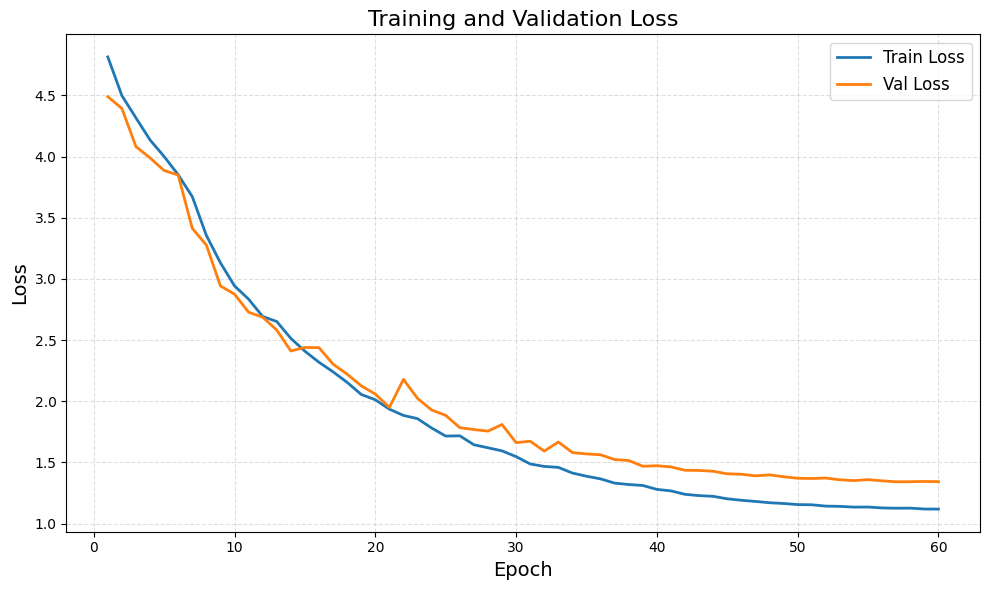

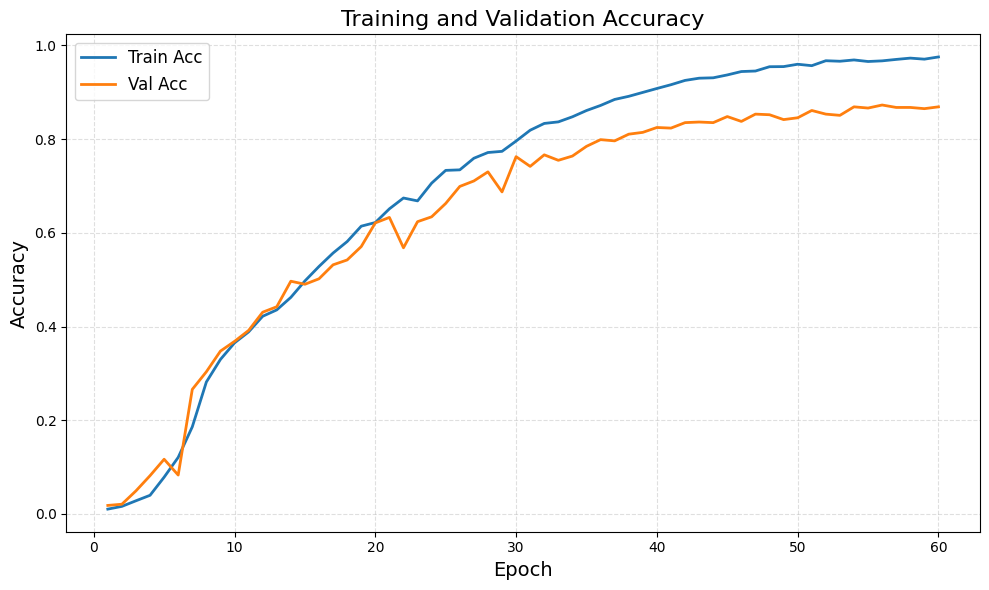

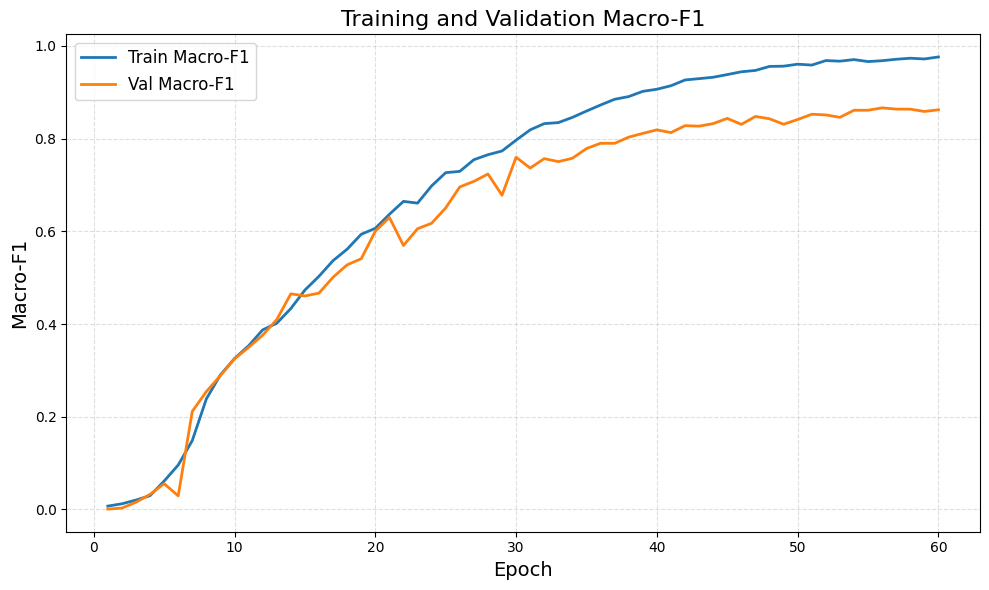

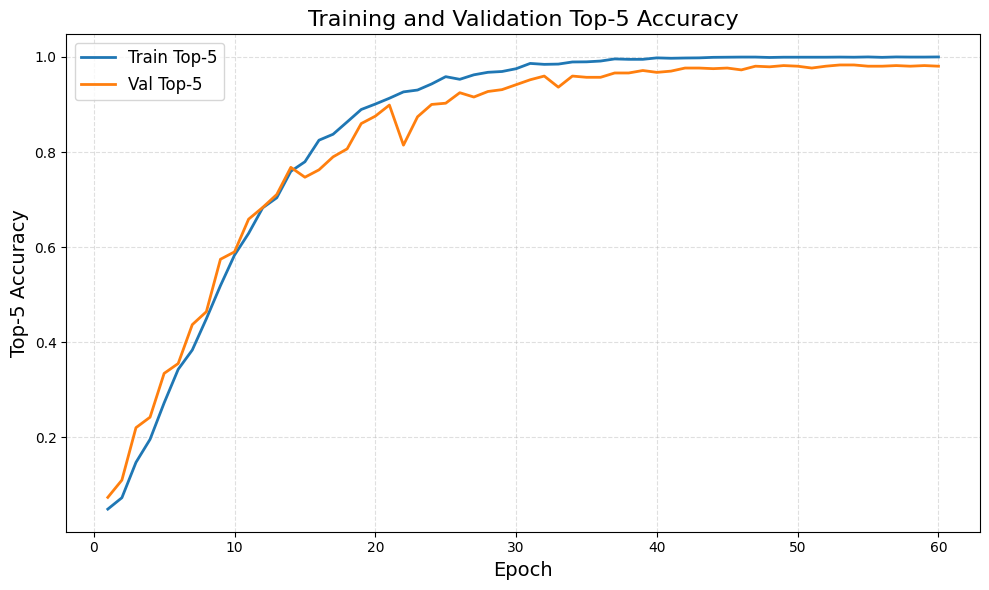


FILES SAVED
 - /kaggle/working/best_improved_late_fusion_transformer.pth
 - /kaggle/working/improved_late_fusion_transformer_training_history.csv
 - /kaggle/working/improved_late_fusion_transformer_per_class_report.csv
 - /kaggle/working/improved_late_fusion_transformer_overall_summary.csv
 - /kaggle/working/improved_late_fusion_transformer_confusion_matrix.csv
 - /kaggle/working/improved_late_fusion_transformer_classification_report.txt
 - /kaggle/working/improved_late_fusion_transformer_label_mapping.csv


In [13]:
# =========================
# FULL TRAINING CODE
# Improved Late Fusion Transformer on concatenated 1536-d features
# Keeps your Step 1 / 2 / 3 / 4 unchanged
# Uses the saved closed-set split files from Step 4
#
# Key improvements:
# - true late-fusion transformer over 3 modality tokens
# - CLS token + modality embeddings
# - class-weighted cross entropy
# - label smoothing
# - cosine annealing scheduler
# - stronger MLP head
# - top-1 and top-5 accuracy
# - best model saving by val accuracy
# =========================

import os
import math
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    accuracy_score,
    confusion_matrix,
    f1_score,
    top_k_accuracy_score
)
from sklearn.utils.class_weight import compute_class_weight

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader


# =========================
# CONFIG
# =========================
SEED = 42
BATCH_SIZE = 128
EPOCHS = 60
LR = 3e-4
MIN_LR = 1e-6
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2
PATIENCE = 12

INPUT_DIM = 1536
TOKEN_DIM = 512
NUM_MODALITIES = 3

NHEAD = 8
NUM_LAYERS = 4
DROPOUT = 0.2
LABEL_SMOOTHING = 0.1

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

SPLIT_DIR = Path("/kaggle/working/features/closed_set_splits")
TRAIN_FILE = SPLIT_DIR / "train_closedset_70_15_15.npz"
VAL_FILE   = SPLIT_DIR / "val_closedset_70_15_15.npz"
TEST_FILE  = SPLIT_DIR / "test_closedset_70_15_15.npz"

MODEL_SAVE_PATH = "/kaggle/working/best_improved_late_fusion_transformer.pth"


# =========================
# REPRODUCIBILITY
# =========================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)


# =========================
# CHECK FILES
# =========================
assert TRAIN_FILE.exists(), f"Missing file: {TRAIN_FILE}"
assert VAL_FILE.exists(), f"Missing file: {VAL_FILE}"
assert TEST_FILE.exists(), f"Missing file: {TEST_FILE}"

print("Train file:", TRAIN_FILE)
print("Val file  :", VAL_FILE)
print("Test file :", TEST_FILE)


# =========================
# LOAD RAW DATA
# =========================
Dtr = np.load(TRAIN_FILE, allow_pickle=True)
Dva = np.load(VAL_FILE, allow_pickle=True)
Dte = np.load(TEST_FILE, allow_pickle=True)

print("\nTrain keys:", Dtr.files)
print("Val keys  :", Dva.files)
print("Test keys :", Dte.files)

X_train_raw = Dtr["X"].astype(np.float32)
y_train_raw = Dtr["y"]
p_train     = Dtr["person_ids"]

X_val_raw = Dva["X"].astype(np.float32)
y_val_raw = Dva["y"]
p_val     = Dva["person_ids"]

X_test_raw = Dte["X"].astype(np.float32)
y_test_raw = Dte["y"]
p_test     = Dte["person_ids"]


# =========================
# BASIC SHAPE CHECK
# =========================
print("\n=========================")
print("SHAPE CHECK")
print("=========================")
print("X_train:", X_train_raw.shape)
print("y_train:", y_train_raw.shape)
print("X_val  :", X_val_raw.shape)
print("y_val  :", y_val_raw.shape)
print("X_test :", X_test_raw.shape)
print("y_test :", y_test_raw.shape)

assert X_train_raw.ndim == 2, f"Expected X_train shape (N,1536), got {X_train_raw.shape}"
assert X_val_raw.ndim == 2, f"Expected X_val shape (N,1536), got {X_val_raw.shape}"
assert X_test_raw.ndim == 2, f"Expected X_test shape (N,1536), got {X_test_raw.shape}"

assert X_train_raw.shape[1] == INPUT_DIM, f"Expected {INPUT_DIM}-d input, got {X_train_raw.shape[1]}"
assert X_val_raw.shape[1] == INPUT_DIM, f"Expected {INPUT_DIM}-d input, got {X_val_raw.shape[1]}"
assert X_test_raw.shape[1] == INPUT_DIM, f"Expected {INPUT_DIM}-d input, got {X_test_raw.shape[1]}"


# =========================
# LABEL CHECK
# =========================
print("\n=========================")
print("RAW LABEL CHECK")
print("=========================")
print("Train unique labels:", np.unique(y_train_raw))
print("Val unique labels  :", np.unique(y_val_raw))
print("Test unique labels :", np.unique(y_test_raw))
print("Train min/max:", np.min(y_train_raw), np.max(y_train_raw))
print("Val min/max  :", np.min(y_val_raw), np.max(y_val_raw))
print("Test min/max :", np.min(y_test_raw), np.max(y_test_raw))

train_set = set(np.unique(y_train_raw))
val_set   = set(np.unique(y_val_raw))
test_set  = set(np.unique(y_test_raw))

print("\nOverlaps:")
print("train ∩ val :", len(train_set & val_set))
print("train ∩ test:", len(train_set & test_set))
print("val ∩ test  :", len(val_set & test_set))

if not (val_set.issubset(train_set) and test_set.issubset(train_set)):
    raise ValueError("Val/Test contain classes not present in train. Recheck split step.")


# =========================
# REMAP LABELS TO 0..C-1
# =========================
all_train_classes = sorted(np.unique(y_train_raw).tolist())
label_to_index = {label: idx for idx, label in enumerate(all_train_classes)}
index_to_label = {idx: label for label, idx in label_to_index.items()}

def remap_labels(y, label_to_index):
    out = []
    for label in y:
        if label not in label_to_index:
            raise ValueError(f"Label {label} not found in training label map.")
        out.append(label_to_index[label])
    return np.array(out, dtype=np.int64)

y_train = remap_labels(y_train_raw, label_to_index)
y_val   = remap_labels(y_val_raw, label_to_index)
y_test  = remap_labels(y_test_raw, label_to_index)

num_classes = len(label_to_index)

print("\n=========================")
print("REMAPPED LABEL CHECK")
print("=========================")
print("num_classes:", num_classes)
print("Chance accuracy:", round(100.0 / num_classes, 4), "%")
print("Train mapped unique:", np.unique(y_train))
print("Val mapped unique  :", np.unique(y_val))
print("Test mapped unique :", np.unique(y_test))
print("Train min/max:", np.min(y_train), np.max(y_train))
print("Val min/max  :", np.min(y_val), np.max(y_val))
print("Test min/max :", np.min(y_test), np.max(y_test))


# =========================
# CLASS DISTRIBUTION
# =========================
train_counts = Counter(y_train)
val_counts = Counter(y_val)
test_counts = Counter(y_test)

print("\n=========================")
print("CLASS DISTRIBUTION")
print("=========================")
print("Min train samples/class:", min(train_counts.values()))
print("Max train samples/class:", max(train_counts.values()))
print("Min val samples/class  :", min(val_counts.values()))
print("Max val samples/class  :", max(val_counts.values()))
print("Min test samples/class :", min(test_counts.values()))
print("Max test samples/class :", max(test_counts.values()))


# =========================
# DATASET
# =========================
class LateFusionFeatureDataset(Dataset):
    """
    Input X is (N, 1536).
    We split it into 3 modality tokens:
        skeleton   = X[:, 0:512]
        silhouette = X[:, 512:1024]
        heatmap    = X[:, 1024:1536]
    Output sample shape: (3, 512)
    """
    def __init__(self, X, y):
        self.X = X.astype(np.float32)
        self.y = y.astype(np.int64)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        x = self.X[idx]

        skel = x[0:512]
        sil  = x[512:1024]
        heat = x[1024:1536]

        tokens = np.stack([skel, sil, heat], axis=0)   # (3, 512)
        label = self.y[idx]

        return (
            torch.tensor(tokens, dtype=torch.float32),
            torch.tensor(label, dtype=torch.long)
        )


# =========================
# DATASETS / LOADERS
# =========================
train_ds = LateFusionFeatureDataset(X_train_raw, y_train)
val_ds   = LateFusionFeatureDataset(X_val_raw, y_val)
test_ds  = LateFusionFeatureDataset(X_test_raw, y_test)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False
)

print("\n=========================")
print("DATA SUMMARY")
print("=========================")
print("Train samples:", len(train_ds))
print("Val samples  :", len(val_ds))
print("Test samples :", len(test_ds))
print("Num classes  :", num_classes)


# =========================
# MODEL
# =========================
class LateFusionTransformer(nn.Module):
    """
    Improved late fusion transformer:
    - takes 3 modality tokens directly
    - adds modality embeddings
    - adds CLS token
    - runs one transformer over [CLS, skel, sil, heat]
    - classifies using CLS output
    """
    def __init__(self, num_classes, dim=512, nhead=8, num_layers=4, dropout=0.2):
        super().__init__()

        self.input_norm = nn.LayerNorm(dim)

        self.cls_token = nn.Parameter(torch.randn(1, 1, dim))
        self.modality_embed = nn.Parameter(torch.randn(1, 3, dim))

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=dim,
            nhead=nhead,
            dim_feedforward=dim * 4,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        self.head = nn.Sequential(
            nn.LayerNorm(dim),
            nn.Linear(dim, 1024),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(1024, 512),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        # x: (B, 3, 512)
        b = x.size(0)

        x = self.input_norm(x)
        x = x + self.modality_embed

        cls = self.cls_token.expand(b, -1, -1)   # (B,1,512)
        x = torch.cat([cls, x], dim=1)           # (B,4,512)

        x = self.transformer(x)                  # (B,4,512)
        cls_out = x[:, 0]                        # (B,512)

        logits = self.head(cls_out)
        return logits


model_late = LateFusionTransformer(
    num_classes=num_classes,
    dim=TOKEN_DIM,
    nhead=NHEAD,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT
).to(DEVICE)

print("\n=========================")
print("MODEL")
print("=========================")
print(model_late)


# =========================
# LOSS / OPTIMIZER / SCHEDULER
# =========================
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=LABEL_SMOOTHING
)

optimizer = torch.optim.AdamW(
    model_late.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS,
    eta_min=MIN_LR
)


# =========================
# METRIC HELPERS
# =========================
def safe_topk_accuracy(y_true, y_prob, k=5):
    k = min(k, y_prob.shape[1])
    try:
        return top_k_accuracy_score(y_true, y_prob, k=k, labels=np.arange(y_prob.shape[1]))
    except Exception:
        topk = np.argsort(-y_prob, axis=1)[:, :k]
        hits = [1 if y_true[i] in topk[i] else 0 for i in range(len(y_true))]
        return float(np.mean(hits))


# =========================
# TRAIN / EVAL FUNCTION
# =========================
def run_one_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None

    if is_train:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    all_preds = []
    all_labels = []
    all_probs = []

    with torch.set_grad_enabled(is_train):
        for x, y in loader:
            x = x.to(DEVICE, non_blocking=True)   # (B,3,512)
            y = y.to(DEVICE, non_blocking=True)

            logits = model(x)
            loss = criterion(logits, y)

            if is_train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

            probs = torch.softmax(logits, dim=1)
            preds = torch.argmax(logits, dim=1)

            total_loss += loss.item() * x.size(0)
            all_preds.extend(preds.detach().cpu().numpy())
            all_labels.extend(y.detach().cpu().numpy())
            all_probs.append(probs.detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)
    all_probs = np.concatenate(all_probs, axis=0)

    acc = accuracy_score(all_labels, all_preds)
    macro_f1 = f1_score(all_labels, all_preds, average="macro", zero_division=0)
    weighted_f1 = f1_score(all_labels, all_preds, average="weighted", zero_division=0)
    top5 = safe_topk_accuracy(all_labels, all_probs, k=5)

    return avg_loss, acc, macro_f1, weighted_f1, top5, all_labels, all_preds, all_probs


# =========================
# TRAINING LOOP
# =========================
best_val_acc = 0.0
best_epoch = 0
patience_counter = 0
history = []

print("\n=========================")
print("START TRAINING")
print("=========================")

for epoch in range(1, EPOCHS + 1):
    current_lr = optimizer.param_groups[0]["lr"]

    train_loss, train_acc, train_macro_f1, train_weighted_f1, train_top5, _, _, _ = run_one_epoch(
        model_late, train_loader, criterion, optimizer
    )

    val_loss, val_acc, val_macro_f1, val_weighted_f1, val_top5, _, _, _ = run_one_epoch(
        model_late, val_loader, criterion, optimizer=None
    )

    scheduler.step()

    history.append({
        "epoch": epoch,
        "lr": current_lr,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "train_macro_f1": train_macro_f1,
        "train_weighted_f1": train_weighted_f1,
        "train_top5": train_top5,
        "val_loss": val_loss,
        "val_acc": val_acc,
        "val_macro_f1": val_macro_f1,
        "val_weighted_f1": val_weighted_f1,
        "val_top5": val_top5
    })

    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] | "
        f"LR: {current_lr:.6f} | "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | Train F1: {train_macro_f1:.4f} | Train Top5: {train_top5:.4f} | "
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | Val F1: {val_macro_f1:.4f} | Val Top5: {val_top5:.4f}"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch
        patience_counter = 0
        torch.save(model_late.state_dict(), MODEL_SAVE_PATH)
        print(f"Best model saved at epoch {epoch}")
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print(f"\nEarly stopping triggered at epoch {epoch}")
        break

print("\n=========================")
print("TRAINING COMPLETE")
print("=========================")
print(f"Best Validation Accuracy: {best_val_acc:.4f}")
print(f"Best Epoch: {best_epoch}")


# =========================
# LOAD BEST MODEL
# =========================
model_late.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))
model_late.eval()


# =========================
# TEST EVALUATION
# =========================
test_loss, test_acc, test_macro_f1, test_weighted_f1, test_top5, y_true, y_pred, y_prob = run_one_epoch(
    model_late, test_loader, criterion, optimizer=None
)

print("\n=========================")
print("FINAL TEST RESULTS")
print("=========================")
print(f"Test Loss       : {test_loss:.4f}")
print(f"Test Accuracy   : {test_acc:.4f}")
print(f"Test Macro F1   : {test_macro_f1:.4f}")
print(f"Test Weighted F1: {test_weighted_f1:.4f}")
print(f"Test Top-5 Acc  : {test_top5:.4f}")


# =========================
# CLASSIFICATION REPORT
# =========================
class_names = [str(index_to_label[i]) for i in range(num_classes)]

report_text = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
)

report_dict = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    output_dict=True,
    zero_division=0
)

print("\n=========================")
print("CLASSIFICATION REPORT")
print("=========================")
print(report_text)


# =========================
# PER-CLASS PERFORMANCE REPORT
# =========================
per_class_rows = []
for cls_name in class_names:
    row = report_dict[cls_name]
    per_class_rows.append({
        "class": cls_name,
        "precision": row["precision"],
        "recall": row["recall"],
        "f1-score": row["f1-score"],
        "support": int(row["support"])
    })

per_class_df = pd.DataFrame(per_class_rows)

print("\n=========================")
print("PER-CLASS PERFORMANCE REPORT")
print("=========================")
print(per_class_df.head())


# =========================
# OVERALL SUMMARY
# =========================
summary_df = pd.DataFrame([
    {"metric": "accuracy",           "value": report_dict["accuracy"]},
    {"metric": "macro_precision",    "value": report_dict["macro avg"]["precision"]},
    {"metric": "macro_recall",       "value": report_dict["macro avg"]["recall"]},
    {"metric": "macro_f1",           "value": report_dict["macro avg"]["f1-score"]},
    {"metric": "weighted_precision", "value": report_dict["weighted avg"]["precision"]},
    {"metric": "weighted_recall",    "value": report_dict["weighted avg"]["recall"]},
    {"metric": "weighted_f1",        "value": report_dict["weighted avg"]["f1-score"]},
    {"metric": "top5_accuracy",      "value": test_top5},
])

print("\n=========================")
print("OVERALL PERFORMANCE SUMMARY")
print("=========================")
print(summary_df)


# =========================
# CONFUSION MATRIX
# =========================
cm = confusion_matrix(y_true, y_pred)
cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)

print("\n=========================")
print("CONFUSION MATRIX")
print("=========================")
print(cm_df.iloc[:10, :10])


# =========================
# TRAINING HISTORY
# =========================
history_df = pd.DataFrame(history)

print("\n=========================")
print("TRAINING HISTORY")
print("=========================")
print(history_df.tail())


# =========================
# PLOTS
# =========================
plt.figure(figsize=(10, 6))
plt.plot(history_df["epoch"], history_df["train_loss"], label="Train Loss", linewidth=2)
plt.plot(history_df["epoch"], history_df["val_loss"], label="Val Loss", linewidth=2)
plt.xlabel("Epoch", fontsize=14)
plt.ylabel("Loss", fontsize=14)
plt.title("Training and Validation Loss", fontsize=16)
plt.legend(fontsize=12)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(history_df["epoch"], history_df["train_acc"], label="Train Acc", linewidth=2)
plt.plot(history_df["epoch"], history_df["val_acc"], label="Val Acc", linewidth=2)
plt.xlabel("Epoch", fontsize=14)
plt.ylabel("Accuracy", fontsize=14)
plt.title("Training and Validation Accuracy", fontsize=16)
plt.legend(fontsize=12)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(history_df["epoch"], history_df["train_macro_f1"], label="Train Macro-F1", linewidth=2)
plt.plot(history_df["epoch"], history_df["val_macro_f1"], label="Val Macro-F1", linewidth=2)
plt.xlabel("Epoch", fontsize=14)
plt.ylabel("Macro-F1", fontsize=14)
plt.title("Training and Validation Macro-F1", fontsize=16)
plt.legend(fontsize=12)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(history_df["epoch"], history_df["train_top5"], label="Train Top-5", linewidth=2)
plt.plot(history_df["epoch"], history_df["val_top5"], label="Val Top-5", linewidth=2)
plt.xlabel("Epoch", fontsize=14)
plt.ylabel("Top-5 Accuracy", fontsize=14)
plt.title("Training and Validation Top-5 Accuracy", fontsize=16)
plt.legend(fontsize=12)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# =========================
# SAVE REPORTS
# =========================
history_df.to_csv("/kaggle/working/improved_late_fusion_transformer_training_history.csv", index=False)
per_class_df.to_csv("/kaggle/working/improved_late_fusion_transformer_per_class_report.csv", index=False)
summary_df.to_csv("/kaggle/working/improved_late_fusion_transformer_overall_summary.csv", index=False)
cm_df.to_csv("/kaggle/working/improved_late_fusion_transformer_confusion_matrix.csv", index=True)

with open("/kaggle/working/improved_late_fusion_transformer_classification_report.txt", "w") as f:
    f.write(report_text)

pd.DataFrame({
    "original_label": list(label_to_index.keys()),
    "mapped_label": list(label_to_index.values())
}).to_csv("/kaggle/working/improved_late_fusion_transformer_label_mapping.csv", index=False)

print("\n=========================")
print("FILES SAVED")
print("=========================")
print(" - /kaggle/working/best_improved_late_fusion_transformer.pth")
print(" - /kaggle/working/improved_late_fusion_transformer_training_history.csv")
print(" - /kaggle/working/improved_late_fusion_transformer_per_class_report.csv")
print(" - /kaggle/working/improved_late_fusion_transformer_overall_summary.csv")
print(" - /kaggle/working/improved_late_fusion_transformer_confusion_matrix.csv")
print(" - /kaggle/working/improved_late_fusion_transformer_classification_report.txt")
print(" - /kaggle/working/improved_late_fusion_transformer_label_mapping.csv")

In [14]:
# =========================
# RANK-WISE / TOP-K ACCURACY
# =========================
import numpy as np
import pandas as pd
import torch

K_VALUES = [1, 3, 5, 10]

model_late.eval()

all_logits = []
all_labels = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        logits = model_late(x)

        all_logits.append(logits.cpu())
        all_labels.append(y.cpu())

all_logits = torch.cat(all_logits, dim=0)   # (N, C)
all_labels = torch.cat(all_labels, dim=0)   # (N,)

print("=========================")
print("RANK / TOP-K ACCURACY")
print("=========================")

rank_results = []

for k in K_VALUES:
    k = min(k, num_classes)
    topk_preds = torch.topk(all_logits, k=k, dim=1).indices   # (N, k)

    correct = topk_preds.eq(all_labels.view(-1, 1)).any(dim=1)
    topk_acc = correct.float().mean().item()

    rank_results.append({
        "rank_k": k,
        "accuracy": topk_acc,
        "accuracy_percent": topk_acc * 100
    })

    print(f"Rank-{k} Accuracy: {topk_acc:.4f} ({topk_acc*100:.2f}%)")

rank_df = pd.DataFrame(rank_results)
print("\nRank Accuracy Table:")
print(rank_df)

rank_df.to_csv("/kaggle/working/improved_late_fusion_transformer_rank_accuracy.csv", index=False)

print("\nSaved:")
print(" - /kaggle/working/improved_late_fusion_transformer_rank_accuracy.csv")

RANK / TOP-K ACCURACY
Rank-1 Accuracy: 0.8651 (86.51%)
Rank-3 Accuracy: 0.9468 (94.68%)
Rank-5 Accuracy: 0.9715 (97.15%)
Rank-10 Accuracy: 0.9870 (98.70%)

Rank Accuracy Table:
   rank_k  accuracy  accuracy_percent
0       1  0.865110         86.511022
1       3  0.946822         94.682229
2       5  0.971466         97.146565
3      10  0.987030         98.702985

Saved:
 - /kaggle/working/improved_late_fusion_transformer_rank_accuracy.csv
